In [1]:
#the idea is we need to load the models
# import sys
# sys.path.append('/data/leslie/sarthak/hyena/hyena-dna/')
import torch
# from evals.evals_utils import Evals

#actually let's first try the manual load
from src.dataloaders.datasets.hg38_char_tokenizer import CharacterTokenizer
from src.models.sequence.dna_embedding import DNAEmbeddingModel
from torch.utils.data import DataLoader
# from src.dataloaders.datasets.ccre_dataset import CcreDataset
# from src.models.sequence.long_conv_lm import ConvLMHeadModel
from src.tasks.decoders import ProfileDecoder
import yaml


In [2]:
tokenizer = CharacterTokenizer( #make sure to fix the tokenizer too
    characters=['A', 'C', 'G', 'T', 'N'],
    model_max_length=1024 + 2,  # add 2 since default adds eos/eos tokens, crop later
    add_special_tokens=False,
    padding_side='left'
)

cfg = '/data/leslie/sarthak/hyena/hyena-dna/configs/evals/profile.yaml'
cfg = yaml.load(open(cfg, 'r'), Loader=yaml.FullLoader)

In [3]:
train_cfg = cfg['train']  # grab section `train` section of config
model_cfg = cfg['model_config']  # grab the `model` section of config
d_output = train_cfg['d_output']  #TODO make it so that we just adjust this with self.classificaiton, no need for evals
print(d_output, model_cfg, train_cfg)
ckpt_path = '/data/leslie/sarthak/hyena/hyena-dna/outputs/2024-06-15/07-49-23-830590/checkpoints/86-val_loss=1472.48523.ckpt'

1 {'_name_': 'dna_embedding', 'd_model': 128, 'n_layer': 2, 'd_inner': 512, 'vocab_size': 16, 'resid_dropout': 0.0, 'embed_dropout': 0.1, 'fused_mlp': False, 'fused_dropout_add_ln': False, 'residual_in_fp32': True, 'pad_vocab_size_multiple': 1, 'return_hidden_state': True, 'layer': {'_name_': 'hyena', 'emb_dim': 5, 'filter_order': 64, 'local_order': 3, 'l_max': 1026, 'modulate': True, 'w': 10, 'lr': '6e-4', 'wd': 0.0, 'lr_pos_emb': 0.0}} {'d_output': 1}


In [4]:
backbone = DNAEmbeddingModel(**model_cfg)
decoder = ProfileDecoder(model_cfg['d_model'], d_output=d_output, l_output=0, mode='pool')
state_dict = torch.load(ckpt_path, map_location='cpu')

In [5]:
state_dict['state_dict']

OrderedDict([('model.backbone.embeddings.word_embeddings.weight',
              tensor([[ 0.9429, -0.3050,  1.3067,  ...,  1.0830,  0.9085, -1.2386],
                      [ 0.5170, -1.4734,  0.9022,  ...,  0.5446,  0.5742, -0.8835],
                      [ 0.9428, -0.3050,  1.3067,  ...,  1.0830,  0.9085, -1.2386],
                      ...,
                      [ 0.9428, -0.3050,  1.3067,  ...,  1.0830,  0.9085, -1.2386],
                      [ 0.9428, -0.3050,  1.3067,  ...,  1.0830,  0.9085, -1.2386],
                      [ 0.9428, -0.3050,  1.3067,  ...,  1.0830,  0.9085, -1.2386]])),
             ('model.backbone.layers.0.mixer.out_proj.weight',
              tensor([[-0.0093, -0.0115,  0.0037,  ...,  0.0412,  0.0850, -0.0243],
                      [-0.0325,  0.0245, -0.0056,  ..., -0.0217,  0.0092,  0.0718],
                      [ 0.0179, -0.0046,  0.0085,  ...,  0.0492, -0.0199, -0.0265],
                      ...,
                      [ 0.0177,  0.0297, -0.0114,  ..., -0

In [6]:
decoder

ProfileDecoder(
  (output_transform_counts): Linear(in_features=128, out_features=1, bias=True)
  (output_transform_profile): Linear(in_features=128, out_features=1, bias=True)
)

In [7]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.nn.modules.utils.consume_prefix_in_state_dict_if_present(
    state_dict["state_dict"], "model."
)
model_state_dict = state_dict["state_dict"]
# need to remove torchmetrics. to remove keys, need to convert to list first
for key in list(model_state_dict.keys()):
    if "torchmetrics" in key:
        model_state_dict.pop(key)
# the state_dict keys slightly mismatch from Lightning..., so we fix it here
decoder_state_dict = {}
decoder_state_dict['output_transform_counts.weight'] = model_state_dict.pop('decoder.0.output_transform_counts.weight')
decoder_state_dict['output_transform_counts.bias'] = model_state_dict.pop('decoder.0.output_transform_counts.bias')
decoder_state_dict['output_transform_profile.weight'] = model_state_dict.pop('decoder.0.output_transform_profile.weight')
decoder_state_dict['output_transform_profile.bias'] = model_state_dict.pop('decoder.0.output_transform_profile.bias')
# now actually load the state dict to the decoder and backbone separately
decoder.load_state_dict(decoder_state_dict, strict=True)
backbone.load_state_dict(model_state_dict, strict=True)
decoder = decoder.to(device).eval()
backbone = backbone.to(device).eval()

In [8]:
#so this setup is great, it enables an easy and uniform way to decide if we want to add the bias or not to the outputs of the decoder!
#the other things we need to do are load the dataset, and so given a sequence, we save all the outputs
#the one we loaded has a bias model of none, so we don't have to worry about it! let's now check to see an output

#we need to load the dataset
from src.dataloaders.datasets.profile_atac import ProfileATAC
dataset = ProfileATAC(max_length = 1024, split = 'test', tokenizer=tokenizer, rc_aug = False, tokenizer_name='char', add_eos='False')

In [21]:
import numpy as np
split = 'test'
data_path = f'/data/leslie/sarthak/data/chrombpnet_test/saved_data_1000/{split}/'
#what we do is load in the numpy arrays
peak_seqs = np.load(data_path+'peak_seqs.npy')
peak_cts = np.load(data_path+'peak_cts.npy')
peak_coords = np.load(data_path+'peak_coords.npy')
nonpeak_seqs = np.load(data_path+'nonpeak_seqs.npy', allow_pickle=True) #oh, obviously these 3 are none...
nonpeak_cts = np.load(data_path+'nonpeak_cts.npy', allow_pickle=True)
nonpeak_coords = np.load(data_path+'nonpeak_coords.npy', allow_pickle=True)
print(peak_seqs.shape, peak_cts.shape, peak_coords.shape, nonpeak_seqs.shape, nonpeak_cts.shape, nonpeak_coords.shape)

(26172, 1024, 4) (26172, 800) (26172, 4) () () ()


In [22]:
print(nonpeak_seqs) #so for test no nonpeaks

None


In [23]:
data_path = f'/data/leslie/sarthak/data/chrombpnet_test/saved_data_1000/valid/'
np.load(data_path+'nonpeak_seqs.npy') #exists for valid...

array([[[0, 1, 0, 0],
        [0, 1, 0, 0],
        [0, 0, 1, 0],
        ...,
        [0, 0, 1, 0],
        [0, 1, 0, 0],
        [0, 1, 0, 0]],

       [[0, 0, 0, 1],
        [0, 0, 0, 1],
        [0, 0, 0, 1],
        ...,
        [0, 0, 1, 0],
        [0, 0, 0, 1],
        [1, 0, 0, 0]],

       [[1, 0, 0, 0],
        [0, 0, 1, 0],
        [0, 1, 0, 0],
        ...,
        [0, 0, 0, 1],
        [0, 0, 1, 0],
        [0, 1, 0, 0]],

       ...,

       [[0, 0, 0, 1],
        [1, 0, 0, 0],
        [0, 0, 1, 0],
        ...,
        [0, 0, 1, 0],
        [1, 0, 0, 0],
        [0, 0, 1, 0]],

       [[0, 0, 0, 1],
        [0, 0, 1, 0],
        [0, 0, 0, 1],
        ...,
        [1, 0, 0, 0],
        [1, 0, 0, 0],
        [0, 0, 1, 0]],

       [[0, 1, 0, 0],
        [0, 1, 0, 0],
        [0, 0, 1, 0],
        ...,
        [0, 0, 0, 1],
        [0, 0, 0, 1],
        [0, 0, 0, 1]]], dtype=int8)

In [9]:
#I fixed it, dataset should be good now
dataset[0][0][0].shape
#so here's how the dataset works
#first you choose the index, then you choose input or output. for input, gives sequence, then onehot sequence
#for output gives the profile and counts

torch.Size([1024])

In [10]:
dataset[0][1][0].shape #this is the proper 800 output!!

torch.Size([800])

In [14]:
#now let's test an input and output
out1 = backbone(dataset[0][0][0].unsqueeze(0).to(device))
print(len(out1))
print(out1[0].shape, out1[1]) #out1[1] is just none, don't care about it

2
torch.Size([1, 1024, 128]) None


In [15]:
#now we have the profile level stuff so we have to go through network then cut off
out2 = decoder(out1[0])
print(len(out2))
print(out2[0].shape, out2[1].shape) #so this is the output of the decoder, the profile and the counts

2
torch.Size([1, 1024, 1]) torch.Size([1, 1])


In [21]:
#the final thigns we do are squeeze it and cut to the middle 800 then convert to numpy
true_counts = dataset[0][1][0].unsqueeze(0).to(device)
# print(true_counts.shape)
if out2[0].shape[1] > true_counts.shape[1]:
    #then we cut off from both ends until we get the same size
    diff = out2[0].shape[1] - true_counts.shape[1]
    start = diff // 2
    end = start + true_counts.shape[1]
    profile_out = out2[0][:, start:end].squeeze()
print(profile_out.shape)

torch.Size([800])


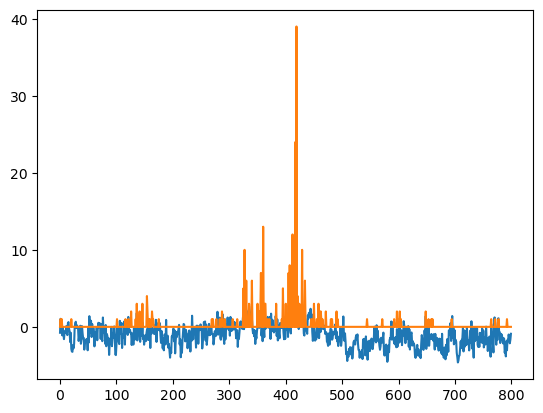

In [24]:
#let's plot this
import matplotlib.pyplot as plt
plt.plot(profile_out.cpu().detach().numpy())
plt.plot(true_counts.squeeze().cpu().detach().numpy())

In [26]:
#This is absolutely terrible...
#let's now look at the other output
print(out2[1], dataset[0][1][1])
#this is actually quite decent!

tensor([[5.9441]], device='cuda:0', grad_fn=<AddmmBackward0>) tensor([5.6454])


In [27]:
#let's go through all the dataset members and save out the results
#we need to save out the profile and counts
len(dataset)

26172

In [34]:
import numpy as np
from tqdm import tqdm
counts_matrix = np.zeros((len(dataset)))
profile_matrix = np.zeros((len(dataset), 800))
print(counts_matrix.shape, profile_matrix.shape)
for i in tqdm(range(len(dataset))):
    out1 = backbone(dataset[i][0][0].unsqueeze(0).to(device))
    out2 = decoder(out1[0])
    true_counts = dataset[i][1][0].unsqueeze(0).to(device)
    if out2[0].shape[1] > true_counts.shape[1]:
        #then we cut off from both ends until we get the same size
        diff = out2[0].shape[1] - true_counts.shape[1]
        start = diff // 2
        end = start + true_counts.shape[1]
        profile_out = out2[0][:, start:end].squeeze()
    #save out the profile and counts
    # print(profile_out.shape)
    # print(out2[1])
    # break
    counts_matrix[i] = out2[1].item()
    profile_matrix[i] = profile_out.cpu().detach().numpy()

(26172,) (26172, 800)


In [37]:
#ensure none of the data is 0
print(np.sum(counts_matrix == 0)) #so all are given an output!

0


In [36]:
#let's save this out now as a compressed numpy array
np.savez_compressed('/data/leslie/sarthak/data/chrombpnet_test/saved_data_1000/profile_nobias.npz', counts=counts_matrix, profile=profile_matrix)

In [ ]:
#let's redo this above but batch to see how much faster it is
#eh whatever we'll just use dataloader, no need to test this
counts_matrix_og = counts_matrix; profile_matrix_og = profile_matrix
counts_matrix = np.zeros((len(dataset)))
profile_matrix = np.zeros((len(dataset), 800))
for i in tqdm(range(len(dataset))):
    out1 = backbone(dataset[i][0][0].unsqueeze(0).to(device))
    out2 = decoder(out1[0])
    true_counts = dataset[i][1][0].unsqueeze(0).to(device)
    if out2[0].shape[1] > true_counts.shape[1]:
        #then we cut off from both ends until we get the same size
        diff = out2[0].shape[1] - true_counts.shape[1]
        start = diff // 2
        end = start + true_counts.shape[1]
        profile_out = out2[0][:, start:end].squeeze()
    #save out the profile and counts
    # print(profile_out.shape)
    # print(out2[1])
    # break
    counts_matrix[i] = out2[1].item()
    profile_matrix[i] = profile_out.cpu().detach().numpy()

# now with the bias model

In [2]:
#restarted the kernel, now we can do the same thing but we want to use the bias model one this time
import torch
import sys
sys.path.append('/data/leslie/sarthak/hyena/hyena-dna/')
from src.dataloaders.datasets.hg38_char_tokenizer import CharacterTokenizer
from src.models.sequence.dna_embedding import DNAEmbeddingModel
from torch.utils.data import DataLoader
from src.tasks.decoders import ProfileDecoder
import yaml

tokenizer = CharacterTokenizer( #make sure to fix the tokenizer too
    characters=['A', 'C', 'G', 'T', 'N'],
    model_max_length=1024 + 2,  # add 2 since default adds eos/eos tokens, crop later
    add_special_tokens=False,
    padding_side='left'
)

cfg = '/data/leslie/sarthak/hyena/hyena-dna/configs/evals/profile.yaml'
cfg = yaml.load(open(cfg, 'r'), Loader=yaml.FullLoader)
train_cfg = cfg['train']  # grab section `train` section of config
model_cfg = cfg['model_config']  # grab the `model` section of config
d_output = train_cfg['d_output']  #TODO make it so that we just adjust this with self.classificaiton, no need for evals
# print(d_output, model_cfg, train_cfg)
backbone = DNAEmbeddingModel(**model_cfg)
decoder = ProfileDecoder(model_cfg['d_model'], d_output=d_output, l_output=0, mode='pool')
ckpt_path = '/data/leslie/sarthak/hyena/hyena-dna/outputs/2024-06-15/07-29-09-511172/checkpoints/86-val_loss=887.93817.ckpt'
bias_model_path = '/data/leslie/sarthak/data/chrombpnet_test/chrombpnet_model_1000/models/bias_model_scaled.h5'

state_dict = torch.load(ckpt_path, map_location='cpu')


In [3]:
backbone = DNAEmbeddingModel(**model_cfg)
decoder = ProfileDecoder(model_cfg['d_model'], d_output=d_output, l_output=0, mode='pool')
state_dict = torch.load(ckpt_path, map_location='cpu')

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.nn.modules.utils.consume_prefix_in_state_dict_if_present(
    state_dict["state_dict"], "model."
)
model_state_dict = state_dict["state_dict"]
# need to remove torchmetrics. to remove keys, need to convert to list first
for key in list(model_state_dict.keys()):
    if "torchmetrics" in key:
        model_state_dict.pop(key)
# the state_dict keys slightly mismatch from Lightning..., so we fix it here
decoder_state_dict = {}
decoder_state_dict['output_transform_counts.weight'] = model_state_dict.pop('decoder.0.output_transform_counts.weight')
decoder_state_dict['output_transform_counts.bias'] = model_state_dict.pop('decoder.0.output_transform_counts.bias')
decoder_state_dict['output_transform_profile.weight'] = model_state_dict.pop('decoder.0.output_transform_profile.weight')
decoder_state_dict['output_transform_profile.bias'] = model_state_dict.pop('decoder.0.output_transform_profile.bias')
# now actually load the state dict to the decoder and backbone separately
decoder.load_state_dict(decoder_state_dict, strict=True)
backbone.load_state_dict(model_state_dict, strict=True)
decoder = decoder.to(device).eval()
backbone = backbone.to(device).eval()

In [4]:
#now we load in the bias model


In [5]:
#let's plot an output with and without the bias, see how much the model actually adds to it...

bias_model_path = '/data/leslie/sarthak/data/chrombpnet_test/chrombpnet_model_1000/models/bias_model_scaled.h5'
#load it
import sys
sys.path.append('/data/leslie/sarthak/chrombpnet/')
from bpnetlite.bpnet import BPNet
#the location is /data/leslie/sarthak/chrombpnet/bpnetlite/bpnet.py
model = BPNet.from_chrombpnet(bias_model_path,trimming=(1024-800)//2)
#eval mode and move it
model.eval().to(device)

BPNet(
  (iconv): Conv1d(4, 128, kernel_size=(21,), stride=(1,), padding=(10,))
  (irelu): ReLU()
  (rconvs): ModuleList(
    (0): Conv1d(128, 128, kernel_size=(3,), stride=(1,), padding=(2,), dilation=(2,))
    (1): Conv1d(128, 128, kernel_size=(3,), stride=(1,), padding=(4,), dilation=(4,))
    (2): Conv1d(128, 128, kernel_size=(3,), stride=(1,), padding=(8,), dilation=(8,))
    (3): Conv1d(128, 128, kernel_size=(3,), stride=(1,), padding=(16,), dilation=(16,))
  )
  (rrelus): ModuleList(
    (0-3): 4 x ReLU()
  )
  (fconv): Conv1d(128, 1, kernel_size=(75,), stride=(1,), padding=(37,))
  (linear): Linear(in_features=128, out_features=1, bias=True)
)

In [6]:
next(model.parameters()).device #so it's on the right device

device(type='cuda', index=0)

In [7]:
#now let's look at an example
from src.dataloaders.datasets.profile_atac import ProfileATAC
dataset = ProfileATAC(max_length = 1024, split = 'test', tokenizer=tokenizer, rc_aug = False, tokenizer_name='char', add_eos='False')


In [8]:
#now let's test an input and output
out1 = backbone(dataset[0][0][0].unsqueeze(0).to(device))
print(len(out1))
print(out1[0].shape, out1[1]) #out1[1] is just none, don't care about it

2
torch.Size([1, 1024, 128]) None


In [9]:
#now we have the profile level stuff so we have to go through network then cut off
out2 = decoder(out1[0])
print(len(out2))
print(out2[0].shape, out2[1].shape) #so this is the output of the decoder, the profile and the counts

2
torch.Size([1, 1024, 1]) torch.Size([1, 1])


In [10]:
#the final thigns we do are squeeze it and cut to the middle 800 then convert to numpy
true_counts = dataset[0][1][0].unsqueeze(0).to(device)
# print(true_counts.shape)
if out2[0].shape[1] > true_counts.shape[1]:
    #then we cut off from both ends until we get the same size
    diff = out2[0].shape[1] - true_counts.shape[1]
    start = diff // 2
    end = start + true_counts.shape[1]
    profile_out = out2[0][:, start:end].squeeze()
print(profile_out.shape)

torch.Size([800])


In [11]:
bias_out = model(dataset[0][0][1].unsqueeze(0).to(device))

In [12]:
print(bias_out[1].shape, bias_out[0].shape)

torch.Size([1, 1]) torch.Size([1, 1, 800])


In [13]:
#now we add to profile_out and the out[1] our bias output
print(out2[1]) #so this does indeed do the heavy lifting!
print(bias_out[1])
print(dataset[0][1][1])
#but remember we have to use torch logsumexp
a=torch.logsumexp(torch.cat([out2[1], bias_out[1]], dim=1), dim=1, keepdim=True)
print(a)

tensor([[5.6410]], device='cuda:0', grad_fn=<AddmmBackward0>)
tensor([[4.0684]], device='cuda:0', grad_fn=<ViewBackward0>)
tensor([5.6454])
tensor([[5.8296]], device='cuda:0', grad_fn=<LogsumexpBackward0>)


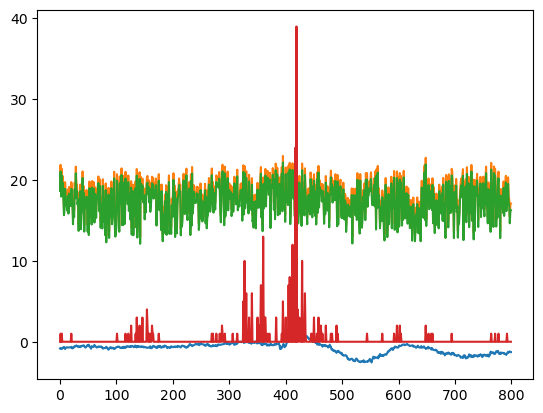

In [20]:
#now let's look at the profiles
import matplotlib.pyplot as plt

plt.plot(profile_out.cpu().detach().numpy())
plt.plot(bias_out[0].squeeze().cpu().detach().numpy())
plt.plot(bias_out[0].squeeze().cpu().detach().numpy() + profile_out[0].squeeze().cpu().detach().numpy())
plt.plot(true_counts.squeeze().cpu().detach().numpy())

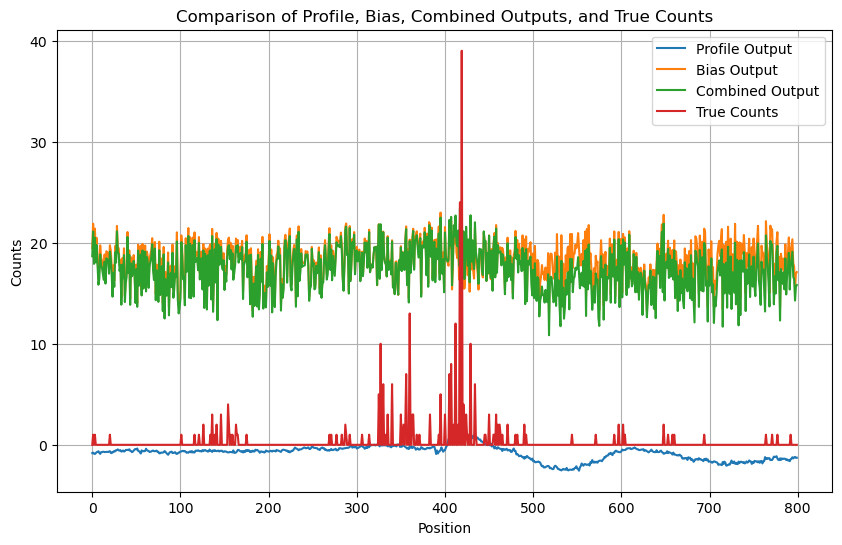

In [15]:
import matplotlib.pyplot as plt
profile_out_np = profile_out.cpu().detach().numpy()
bias_out_np = bias_out[0].squeeze().cpu().detach().numpy()
combined_out_np = bias_out_np + profile_out_np
true_counts_np = true_counts.squeeze().cpu().detach().numpy()

# Create the plot
plt.figure(figsize=(10, 6))

# Plot each series with a label
plt.plot(profile_out_np, label='Profile Output')
plt.plot(bias_out_np, label='Bias Output')
plt.plot(combined_out_np, label='Combined Output')
plt.plot(true_counts_np, label='True Counts')

# Add a legend
plt.legend(loc='best')

# Add axis labels and a title
plt.xlabel('Position')
plt.ylabel('Counts')
plt.title('Comparison of Profile, Bias, Combined Outputs, and True Counts')

# Add grid for better readability
plt.grid(True)

# Optionally, customize the plot style
# plt.style.use('seaborn-darkgrid')

# Show the plot
plt.show()

In [25]:
#now do the softmax
print(profile_out.shape)
print(bias_out[0].shape)

sum_out = profile_out + bias_out[0].squeeze()
print(sum_out.shape)
print(sum_out.softmax(dim=0).shape)
print(sum_out.softmax(dim=0).sum())

torch.Size([800])
torch.Size([1, 1, 800])
torch.Size([800])
torch.Size([800])
tensor(1., device='cuda:0', grad_fn=<SumBackward0>)


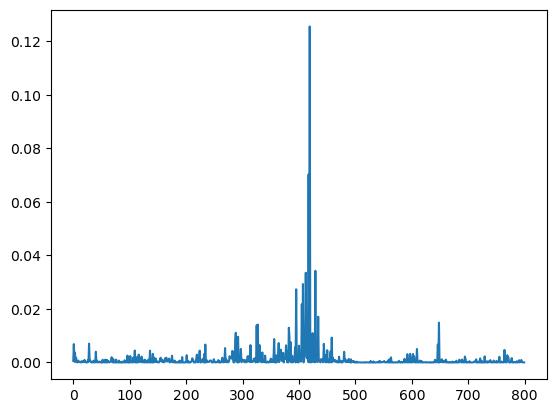

In [26]:
soft_out = sum_out.softmax(dim=0)
plt.plot(soft_out.cpu().detach().numpy())
#oh... wait what?

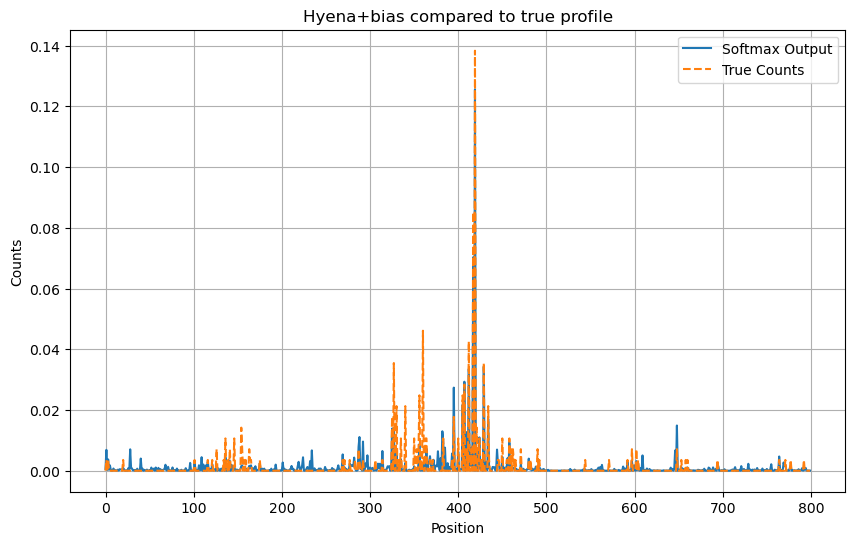

In [30]:
soft_out_np = soft_out.cpu().detach().numpy()
true_counts_np = true_counts.squeeze().cpu().detach().numpy()

# Create the plot
plt.figure(figsize=(10, 6))

# Plot each series with a label
soft_out_np = soft_out_np / soft_out_np.sum()
plt.plot(soft_out_np, label='Softmax Output', )
true_counts_np = true_counts_np / true_counts_np.sum()
plt.plot(true_counts_np, label='True Counts', linestyle='--')

# Add a legend
plt.legend(loc='best')

# Add axis labels and a title
plt.xlabel('Position')
plt.ylabel('Counts')
plt.title('Hyena+bias compared to true profile')

# Add grid for better readability
plt.grid(True)

In [24]:
#finally let's use torch nll loss to see how large the loss is for this
def cbpnet_multinomial_nll(logits,true_counts, len_batch=None, ignore_index=-100, mask = True):

    """A loss function based on the multinomial negative log-likelihood.
    modified by me to include things like doing thE log softmax and deal with more complex tracking

    This loss function takes in a tensor of normalized log probabilities such
    that the sum of each row is equal to 1 (e.g. from a log softmax) and
    an equal sized tensor of true counts and returns the probability of
    observing the true counts given the predicted probabilities under a
    multinomial distribution. Can accept tensors with 2 or more dimensions
    and averages over all except for the last axis, which is the number
    of categories.

    Adapted from Alex Tseng.

    Parameters
    ----------
    logps: torch.tensor, shape=(n, ..., L)
        A tensor with `n` examples and `L` possible categories. 

    true_counts: torch.tensor, shape=(n, ..., L)
        A tensor with `n` examples and `L` possible categories.

    Returns
    -------
    loss: float
        The multinomial log likelihood loss of the true counts given the
        predicted probabilities, averaged over all examples and all other
        dimensions.
    """
    if isinstance(logits, tuple): #for wandb tracking, it inputs logits here, since then it's a tuple
        logits = logits[0]
        true_counts = true_counts[0]
    #we also need to make sure that we have the right shape
    logits = logits.squeeze(); true_counts = true_counts.squeeze()
    # if logits.shape[1] > true_counts.shape[1]: #added it in the tasks instead
    #     #then we cut off from both ends until we get the same size
    #     diff = logits.shape[1] - true_counts.shape[1]
    #     start = diff // 2
    #     end = start + true_counts.shape[1]
    #     logits = logits[:, start:end]
        # logits = logits[:,diff//2:-diff//2]
    logps = torch.log_softmax(logits, dim=-1)
    log_fact_sum = torch.lgamma(torch.sum(true_counts, dim=-1) + 1)
    log_prod_fact = torch.sum(torch.lgamma(true_counts + 1), dim=-1)
    log_prod_exp = torch.sum(true_counts * logps, dim=-1)
    return (-log_fact_sum + log_prod_fact - log_prod_exp).mean()

#let's test this
cbpnet_multinomial_nll(profile_out+bias_out[0], true_counts)
#this loss is smaller than average? wtf??

tensor(313.3624, device='cuda:0', grad_fn=<MeanBackward0>)

In [29]:
#let's now go through and save out the results
from tqdm import tqdm
import numpy as np
counts_matrix = np.zeros((len(dataset)))
profile_matrix = np.zeros((len(dataset), 800))
print(counts_matrix.shape, profile_matrix.shape)
for i in tqdm(range(len(dataset))):
    out1 = backbone(dataset[i][0][0].unsqueeze(0).to(device))
    out2 = decoder(out1[0])
    true_counts = dataset[i][1][0].unsqueeze(0).to(device)
    if out2[0].shape[1] > true_counts.shape[1]:
        #then we cut off from both ends until we get the same size
        diff = out2[0].shape[1] - true_counts.shape[1]
        start = diff // 2
        end = start + true_counts.shape[1]
        profile_out = out2[0][:, start:end].squeeze()
    bias_out = model(dataset[i][0][1].unsqueeze(0).to(device))
    combined_out = profile_out + bias_out[0].squeeze()
    counts_out = torch.logsumexp(torch.cat([out2[1], bias_out[1]], dim=1), dim=1, keepdim=True)
    counts_matrix[i] = counts_out.item()
    profile_matrix[i] = combined_out.cpu().detach().numpy()
    # print(combined_out.shape, profile_out.shape, bias_out[0].shape)
    # print(counts_out.shape, out2[1].shape, bias_out[1].shape)

(26172,) (26172, 800)


100%|██████████| 26172/26172 [02:36<00:00, 167.37it/s]


In [30]:
#save out the data again
np.savez_compressed('/data/leslie/sarthak/data/chrombpnet_test/saved_data_1000/profile_bias.npz', counts=counts_matrix, profile=profile_matrix)

# chrombpnet model

In [2]:
#final thing, the tensorflow model results!
#hmmm, seems the tf thing doesn't actually load the weights, let's find where weights are loaded
#hmmm, yes it should say got the model, it probably didn't because we were calling the chrombpnet model one but that one doesn't exist!!

#hmmm, let's try to load the tensorflow model to compare...
#if it can load the data, that's good!


import argparse
import copy
import sys
sys.path.insert(0,'/data/leslie/sarthak/chrombpnet/')
# print(sys.path)
sys.path.append('/data/leslie/sarthak/chrombpnet/chrombpnet/')
#path of test args
#/data/leslie/sarthak/chrombpnet/chrombpnet/test_args.py
from test_args import main
sys.argv = [
    'test_args.py', 'pipeline',
    '-ibam', '/data/leslie/sarthak/data/chrombpnet_test/merged.bam',
    '-d', 'ATAC',
    '-g', '/data/leslie/sarthak/data/chrombpnet_test/hg38.fa',
    '-c', '/data/leslie/sarthak/data/chrombpnet_test/hg38.chrom.sizes',
    '-p', '/data/leslie/sarthak/data/chrombpnet_test/peaks_no_blacklist.bed',
    '-n', '/data/leslie/sarthak/data/chrombpnet_test/output_negatives.bed',
    '-fl', '/data/leslie/sarthak/data/chrombpnet_test/splits/fold_0.json',
    '-b', '/data/leslie/sarthak/data/chrombpnet_test/bias_model_1000/models/k562_bias.h5',
    '-o', '/data/leslie/sarthak/data/chrombpnet_test/chrombpnet_model/',
    '-il', '1024',
    '-ol', '800'
]
args = main()
#and now we can simulate our args

#now we modify args
import json
import os
if args.file_prefix:
    fpx = args.file_prefix+"_"
else:
    fpx = ""

args.output_prefix = os.path.join(args.output_dir,"auxiliary/{}data".format(fpx))
args.plus_shift = None
args.minus_shift = None
args.bigwig = os.path.join(args.output_dir,"auxiliary/{}data_unstranded.bw".format(fpx))
args.output_prefix = os.path.join(args.output_dir,"evaluation/{}bw_shift_qc".format(fpx))
folds = json.load(open(args.chr_fold_path))
args.chr = folds["valid"][0]
args.pwm_width=24

import chrombpnet.training.predict as predict
args_copy = copy.deepcopy(args)
args_copy.output_prefix = os.path.join(args_copy.output_dir,"evaluation/bias")
args_copy.peaks = os.path.join(args.output_dir,"auxiliary/{}filtered.peaks.bed".format(fpx))
args_copy.model_h5 = args.bias_model_path
args_copy.nonpeaks = "None"
print(args_copy.model_h5)

metrics_dictionary = {"counts_metrics":{}, "profile_metrics":{}}

# get model architecture to load - can load .hdf5 and .weights/.arch
# model=predict.load_model_wrapper(args_copy)
#/data/leslie/sarthak/data/chrombpnet_test/bias_model_1000/models/k562_bias.h5

Namespace(cmd='pipeline', genome='/data/leslie/sarthak/data/chrombpnet_test/hg38.fa', chrom_sizes='/data/leslie/sarthak/data/chrombpnet_test/hg38.chrom.sizes', input_bam_file='/data/leslie/sarthak/data/chrombpnet_test/merged.bam', input_fragment_file=None, input_tagalign_file=None, output_dir='/data/leslie/sarthak/data/chrombpnet_test/chrombpnet_model/', data_type='ATAC', peaks='/data/leslie/sarthak/data/chrombpnet_test/peaks_no_blacklist.bed', nonpeaks='/data/leslie/sarthak/data/chrombpnet_test/output_negatives.bed', chr_fold_path='/data/leslie/sarthak/data/chrombpnet_test/splits/fold_0.json', outlier_threshold=0.9999, ATAC_ref_path=None, DNASE_ref_path=None, num_samples=10000, inputlen=1024, outputlen=800, seed=1234, epochs=50, early_stop=5, learning_rate=0.001, trackables=['logcount_predictions_loss', 'loss', 'logits_profile_predictions_loss', 'val_logcount_predictions_loss', 'val_loss', 'val_logits_profile_predictions_loss'], architecture_from_file=None, file_prefix=None, html_pref

In [3]:
args_copy.model_h5 = '/data/leslie/sarthak/data/chrombpnet_test/chrombpnet_model_1000/models/chrombpnet.h5'
model = predict.load_model_wrapper(args_copy)

2024-06-17 13:07:44.427153: I tensorflow/core/platform/cpu_feature_guard.cc:151] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  SSE4.1 SSE4.2 AVX AVX2 FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.
2024-06-17 13:07:50.896181: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1525] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 6688 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 2080, pci bus id: 0000:02:00.0, compute capability: 7.5
2024-06-17 13:07:50.897985: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1525] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 6470 MB memory:  -> device: 1, name: NVIDIA GeForce RTX 2080, pci bus id: 0000:03:00.0, compute capability: 7.5
2024-06-17 13:07:50.898853: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1525] Created device /job:localhost/r

got the model


In [4]:
model.summary()

Model: "model"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 sequence (InputLayer)          [(None, 1024, 4)]    0           []                               
                                                                                                  
 model_wo_bias (Functional)     [(None, 800),        4017154     ['sequence[0][0]']               
                                 (None, 1)]                                                       
                                                                                                  
 model (Functional)             [(None, 800),        217730      ['sequence[0][0]']               
                                 (None, 1)]                                                       
                                                                                              

In [5]:
#I think that's good! Now we can import the dataset and...
#Oh no, the dataset... huh let's manually do thi stuff then...
import numpy as np
data_path = f'/data/leslie/sarthak/data/chrombpnet_test/saved_data_1000/test/'
peak_seqs = np.load(data_path+'peak_seqs.npy')
peak_cts = np.load(data_path+'peak_cts.npy')
peak_coords = np.load(data_path+'peak_coords.npy')
print(peak_seqs.shape, peak_cts.shape, peak_coords.shape)

(26172, 1024, 4) (26172, 800) (26172, 4)


In [6]:
#we already have the data let's just put it through! after we unsqueeze it
input_data = peak_seqs[0].reshape(1,1024,4)
print(input_data.shape)

(1, 1024, 4)


In [7]:
#now evaluate with our model
output = model.predict(input_data)
print(output[0].shape)
print(output[1].shape)

2024-06-17 13:07:54.760641: I tensorflow/stream_executor/cuda/cuda_dnn.cc:368] Loaded cuDNN version 8907
2024-06-17 13:07:55.698008: W tensorflow/stream_executor/gpu/asm_compiler.cc:111] *** WARNING *** You are using ptxas 11.0.221, which is older than 11.1. ptxas before 11.1 is known to miscompile XLA code, leading to incorrect results or invalid-address errors.

You may not need to update to CUDA 11.1; cherry-picking the ptxas binary is often sufficient.


(1, 800)
(1, 1)


In [8]:
#now for this same example let's go ahead and see the model outputs split up again
bias_model = model.get_layer('model')
bias_model.summary()

Model: "model"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 sequence (InputLayer)          [(None, 1024, 4)]    0           []                               
                                                                                                  
 bpnet_1st_conv (Conv1D)        (None, 1004, 128)    10880       ['sequence[0][0]']               
                                                                                                  
 bpnet_1conv (Conv1D)           (None, 1000, 128)    49280       ['bpnet_1st_conv[0][0]']         
                                                                                                  
 bpnet_1crop (Cropping1D)       (None, 1000, 128)    0           ['bpnet_1st_conv[0][0]']         
                                                                                              

In [9]:
#now get the full model too
full_model = model.get_layer('model_wo_bias')
full_model.summary()

Model: "model_wo_bias"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 sequence (InputLayer)          [(None, 1024, 4)]    0           []                               
                                                                                                  
 wo_bias_bpnet_1st_conv (Conv1D  (None, 1004, 512)   43520       ['sequence[0][0]']               
 )                                                                                                
                                                                                                  
 wo_bias_bpnet_1conv (Conv1D)   (None, 1000, 512)    786944      ['wo_bias_bpnet_1st_conv[0][0]'] 
                                                                                                  
 wo_bias_bpnet_1crop (Cropping1  (None, 1000, 512)   0           ['wo_bias_bpnet_1st_c

 wo_bias_bpnet_3conv (Conv1D)   (None, 976, 512)     786944      ['add_1[0][0]']                  
                                                                                                  
 wo_bias_bpnet_3crop (Cropping1  (None, 976, 512)    0           ['add_1[0][0]']                  
 D)                                                                                               
                                                                                                  
 add_2 (Add)                    (None, 976, 512)     0           ['wo_bias_bpnet_3conv[0][0]',    
                                                                  'wo_bias_bpnet_3crop[0][0]']    
                                                                                                  
 wo_bias_bpnet_4conv (Conv1D)   (None, 944, 512)     786944      ['add_2[0][0]']                  
                                                                                                  
 wo_bias_b

In [10]:
#now let's find all the sub parts
#first the bias model output
bias_output = bias_model.predict(input_data)
print(bias_output[0].shape)
print(bias_output[1].shape)

(1, 800)
(1, 1)


In [11]:
other_model_output = full_model.predict(input_data)
print(other_model_output[0].shape)
print(other_model_output[1].shape)

(1, 800)
(1, 1)


In [12]:
model_output = model.predict(input_data)
print(model_output[0].shape)
print(model_output[1].shape)

(1, 800)
(1, 1)


In [13]:
print(bias_output[1], other_model_output[1], model_output[1])
#bias output is very similar, but clealry it's overshooting here!
print(np.log(sum(peak_cts[0])))

[[4.09836]] [[6.0460367]] [[6.1793475]]
5.641907070938114


findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not

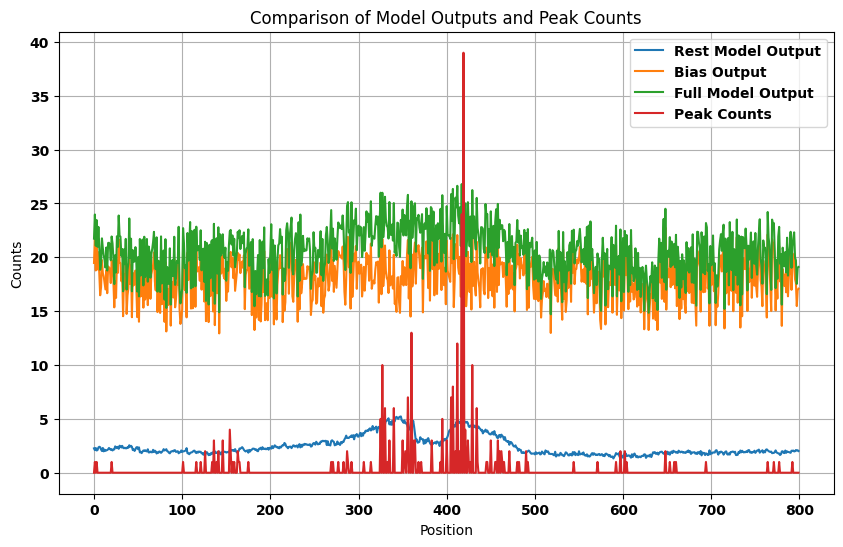

In [22]:
import matplotlib.pyplot as plt
%matplotlib inline
#let's plot the subparts again
plt.figure(figsize=(10, 6))

# Plot each series with a label and customize the appearance
plt.plot(other_model_output[0].squeeze(), label='Rest Model Output')
plt.plot(bias_output[0].squeeze(), label='Bias Output')
plt.plot(model_output[0].squeeze(), label='Full Model Output')
plt.plot(peak_cts[0].squeeze(), label='Peak Counts')

# Add a legend
plt.legend(loc='best')

# Add axis labels and a title
plt.xlabel('Position')
plt.ylabel('Counts')
plt.title('Comparison of Model Outputs and Peak Counts')

# Add grid for better readability
plt.grid(True)
plt.show()

In [15]:
plt.plot([0,1],[0,2])

In [27]:
#the final thing is we will save it all out
from tqdm import tqdm
import numpy as np
counts_matrix = np.zeros((peak_seqs.shape[0]))
profile_matrix = np.zeros((peak_seqs.shape[0], 800))

batch_size = 128

for i in tqdm(range(0,peak_seqs.shape[0], batch_size)):
    end = i+batch_size
    if end > peak_seqs.shape[0]:
        end = peak_seqs.shape[0]
    out = model.predict(peak_seqs[i:end])
    counts_matrix[i:end] = out[1].squeeze()
    profile_matrix[i:end] = out[0].squeeze()
    # print(out[1].shape, out[0].shape)
    # break
    # print(combined_out.shape, profile_out.shape, bias_out[0].shape)
    # print(counts_out.shape, out2[1].shape, bias_out[1].shape)

100%|██████████| 205/205 [00:58<00:00,  3.48it/s]


In [28]:
#print the number of 0 elements in the counts
print(np.sum(counts_matrix == 0))

0


In [29]:
#save ti out again
np.savez_compressed('/data/leslie/sarthak/data/chrombpnet_test/saved_data_1000/profile_chbpnet.npz', counts=counts_matrix, profile=profile_matrix)

# evaluate results!

In [40]:
#let's start by looking at the counts data
#first load in all the data
import numpy as np
nobias = np.load('/data/leslie/sarthak/data/chrombpnet_test/saved_data_1000/profile_nobias.npz')
bias = np.load('/data/leslie/sarthak/data/chrombpnet_test/saved_data_1000/profile_bias.npz')
chbpnet = np.load('/data/leslie/sarthak/data/chrombpnet_test/saved_data_1000/profile_chbpnet.npz')
true = np.load('/data/leslie/sarthak/data/chrombpnet_test/saved_data_1000/true_data.npz')

In [39]:
#now load in the dataset as well
import sys
sys.path.append('/data/leslie/sarthak/hyena/hyena-dna/')
from src.dataloaders.datasets.profile_atac import ProfileATAC
from src.dataloaders.datasets.hg38_char_tokenizer import CharacterTokenizer
tokenizer = CharacterTokenizer( #make sure to fix the tokenizer too
    characters=['A', 'C', 'G', 'T', 'N'],
    model_max_length=1024 + 2,  # add 2 since default adds eos/eos tokens, crop later
    add_special_tokens=False,
    padding_side='left'
)
dataset = ProfileATAC(max_length = 1024, split = 'test', tokenizer=tokenizer, rc_aug = False, tokenizer_name='char', add_eos='False')
#now produce a list of all the counts results
true_counts = np.zeros((len(dataset)))
true_profiles = np.zeros((len(dataset), 800))
for i in range(len(dataset)):
    true_counts[i] = dataset[i][1][1].item()
    true_profiles[i] = dataset[i][1][0].squeeze().cpu().detach().numpy()

In [40]:
#let's save it out
np.savez_compressed('/data/leslie/sarthak/data/chrombpnet_test/saved_data_1000/true_data.npz', counts=true_counts, profile=true_profiles)

In [5]:
bias['counts'].shape

(26172,)

In [6]:
true_counts.shape

(26172,)

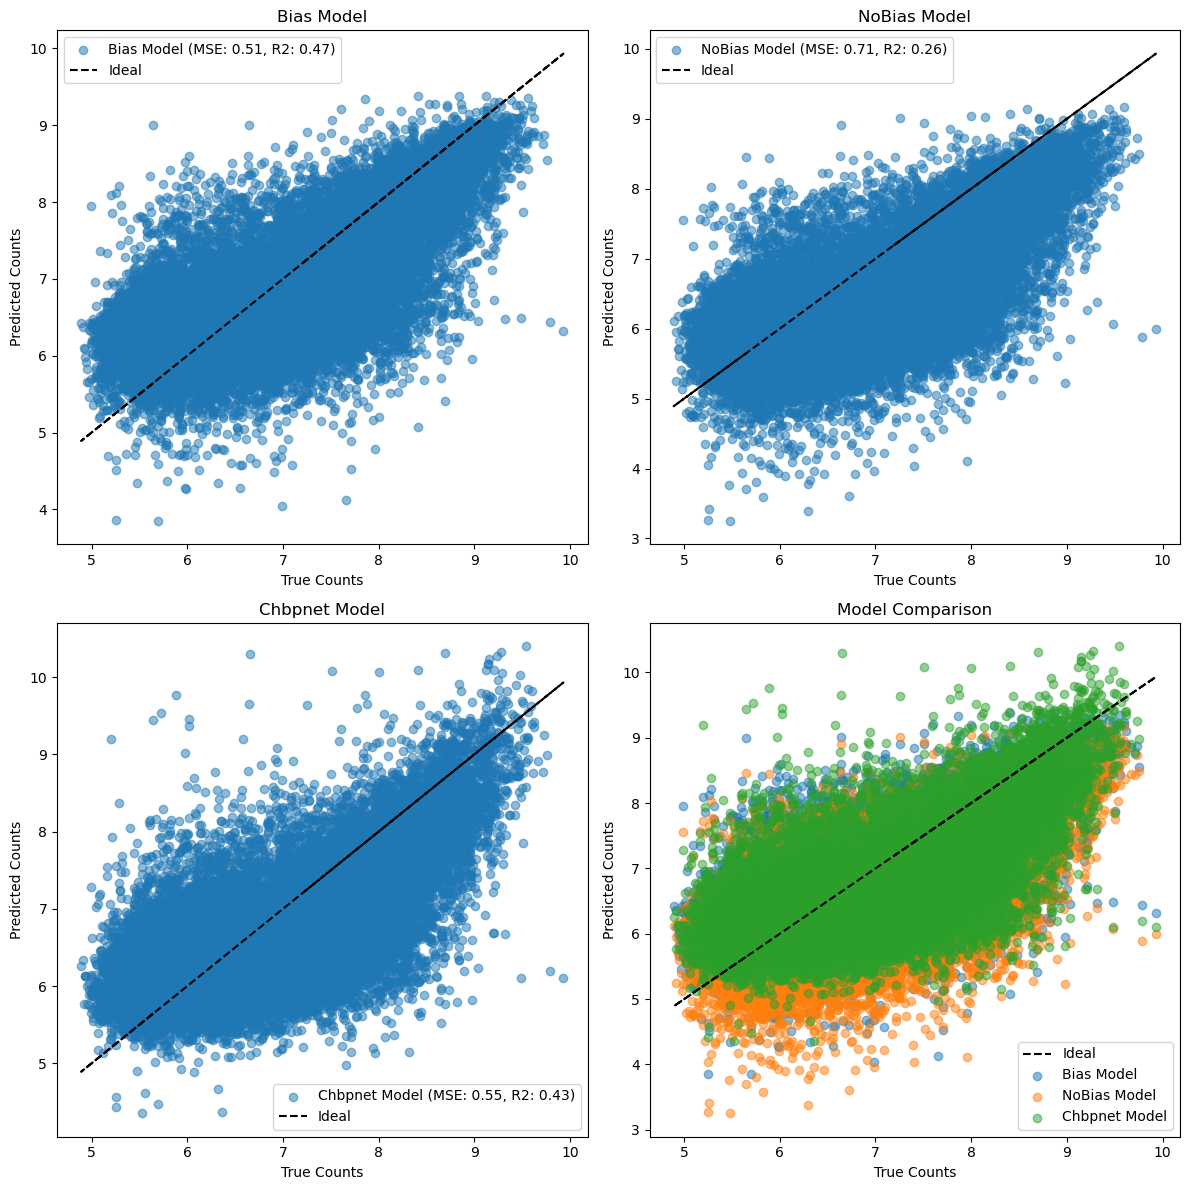

In [46]:
#now let's compare the models, first just the counts
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, r2_score

bias_counts = bias['counts']
nobias_counts = nobias['counts']
chbpnet_counts = chbpnet['counts']

# Calculate summary statistics
bias_mse = mean_squared_error(true_counts, bias_counts)
nobias_mse = mean_squared_error(true_counts, nobias_counts)
chbpnet_mse = mean_squared_error(true_counts, chbpnet_counts)

bias_r2 = r2_score(true_counts, bias_counts)
nobias_r2 = r2_score(true_counts, nobias_counts)
chbpnet_r2 = r2_score(true_counts, chbpnet_counts)

# Create a figure
plt.figure(figsize=(12, 12))

# Scatter plots
plt.subplot(2, 2, 1)
plt.scatter(true_counts, bias_counts, alpha=0.5, label=f'Bias Model (MSE: {bias_mse:.2f}, R2: {bias_r2:.2f})')
plt.xlabel('True Counts')
plt.ylabel('Predicted Counts')
plt.title('Bias Model')
plt.plot(true_counts, true_counts, 'k--', label='Ideal')
#add the 1,1 line between the minimum and maximum
plt.plot()
plt.legend()

plt.subplot(2, 2, 2)
plt.scatter(true_counts, nobias_counts, alpha=0.5, label=f'NoBias Model (MSE: {nobias_mse:.2f}, R2: {nobias_r2:.2f})')
plt.xlabel('True Counts')
plt.ylabel('Predicted Counts')
plt.title('NoBias Model')
plt.plot(true_counts, true_counts, 'k--', label='Ideal')
plt.legend()

plt.subplot(2, 2, 3)
plt.scatter(true_counts, chbpnet_counts, alpha=0.5, label=f'Chbpnet Model (MSE: {chbpnet_mse:.2f}, R2: {chbpnet_r2:.2f})')
plt.xlabel('True Counts')
plt.ylabel('Predicted Counts')
plt.title('Chbpnet Model')
plt.plot(true_counts, true_counts, 'k--', label='Ideal')
plt.legend()

# Overlay plot
plt.subplot(2, 2, 4)
plt.plot(true_counts, true_counts, 'k--', label='Ideal')
plt.scatter(true_counts, bias_counts, alpha=0.5, label='Bias Model')
plt.scatter(true_counts, nobias_counts, alpha=0.5, label='NoBias Model')
plt.scatter(true_counts, chbpnet_counts, alpha=0.5, label='Chbpnet Model')
plt.xlabel('True Counts')
plt.ylabel('Predicted Counts')
plt.title('Model Comparison')
plt.legend()

plt.tight_layout()

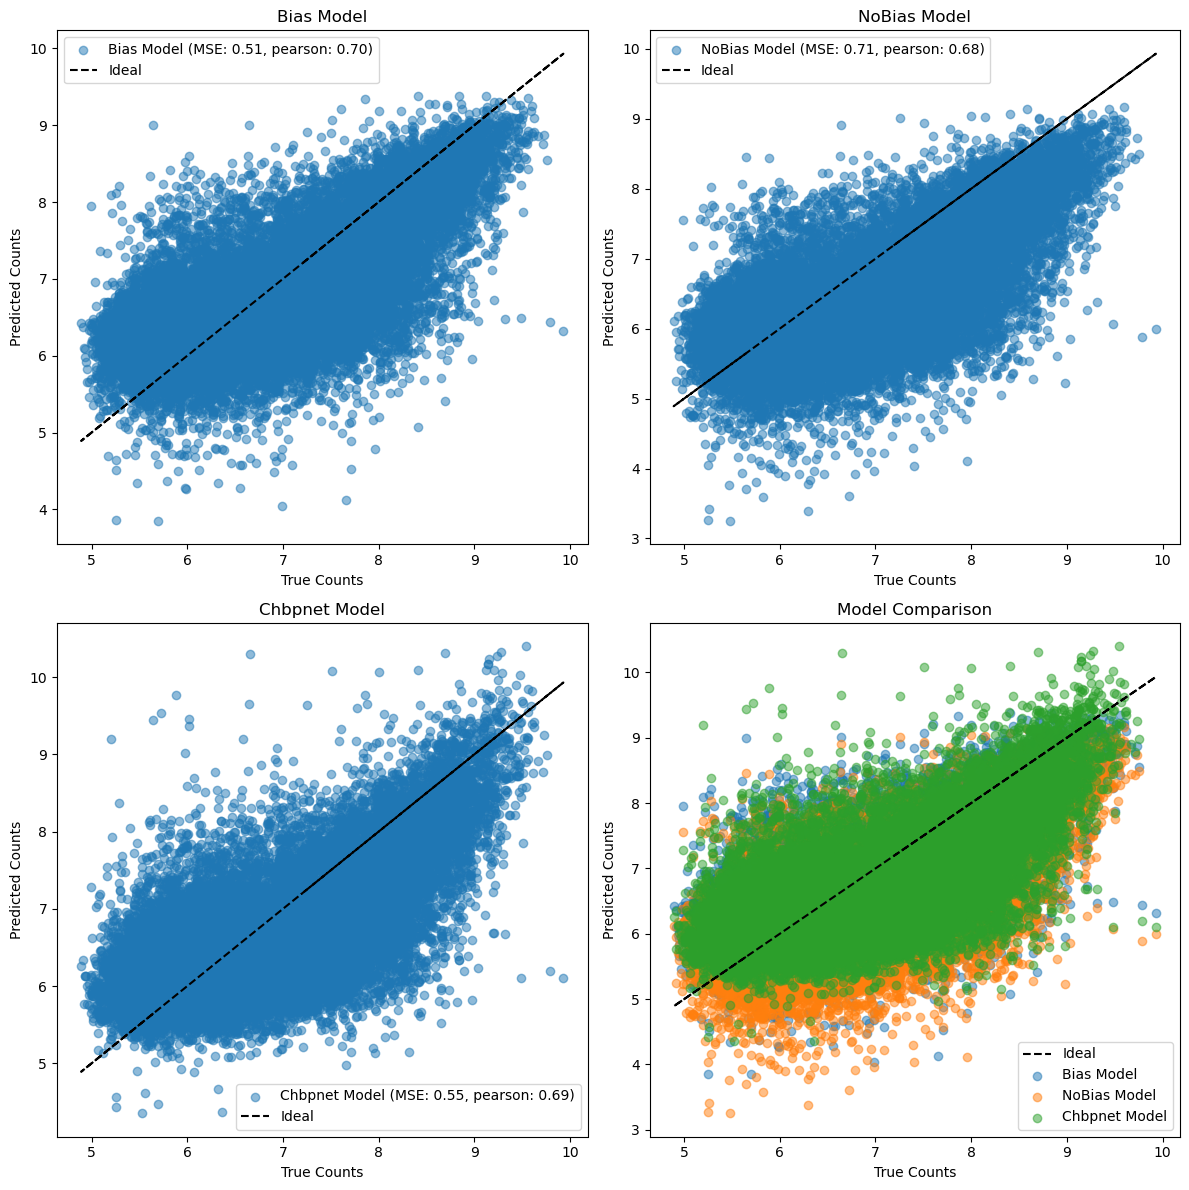

In [50]:
#now let's compare the models, first just the counts
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error
from scipy.stats import pearsonr

bias_counts = bias['counts']
nobias_counts = nobias['counts']
chbpnet_counts = chbpnet['counts']

# Calculate summary statistics
bias_mse = mean_squared_error(true_counts, bias_counts)
nobias_mse = mean_squared_error(true_counts, nobias_counts)
chbpnet_mse = mean_squared_error(true_counts, chbpnet_counts)

#calculate the pearson correlation
bias_r2 = pearsonr(true_counts, bias_counts)[0]
nobias_r2 = pearsonr(true_counts, nobias_counts)[0]
chbpnet_r2 = pearsonr(true_counts, chbpnet_counts)[0]

# Create a figure
plt.figure(figsize=(12, 12))

# Scatter plots
plt.subplot(2, 2, 1)
plt.scatter(true_counts, bias_counts, alpha=0.5, label=f'Bias Model (MSE: {bias_mse:.2f}, pearson: {bias_r2:.2f})')
plt.xlabel('True Counts')
plt.ylabel('Predicted Counts')
plt.title('Bias Model')
plt.plot(true_counts, true_counts, 'k--', label='Ideal')
#add the 1,1 line between the minimum and maximum
plt.plot()
plt.legend()

plt.subplot(2, 2, 2)
plt.scatter(true_counts, nobias_counts, alpha=0.5, label=f'NoBias Model (MSE: {nobias_mse:.2f}, pearson: {nobias_r2:.2f})')
plt.xlabel('True Counts')
plt.ylabel('Predicted Counts')
plt.title('NoBias Model')
plt.plot(true_counts, true_counts, 'k--', label='Ideal')
plt.legend()

plt.subplot(2, 2, 3)
plt.scatter(true_counts, chbpnet_counts, alpha=0.5, label=f'Chbpnet Model (MSE: {chbpnet_mse:.2f}, pearson: {chbpnet_r2:.2f})')
plt.xlabel('True Counts')
plt.ylabel('Predicted Counts')
plt.title('Chbpnet Model')
plt.plot(true_counts, true_counts, 'k--', label='Ideal')
plt.legend()

# Overlay plot
plt.subplot(2, 2, 4)
plt.plot(true_counts, true_counts, 'k--', label='Ideal')
plt.scatter(true_counts, bias_counts, alpha=0.5, label='Bias Model')
plt.scatter(true_counts, nobias_counts, alpha=0.5, label='NoBias Model')
plt.scatter(true_counts, chbpnet_counts, alpha=0.5, label='Chbpnet Model')
plt.xlabel('True Counts')
plt.ylabel('Predicted Counts')
plt.title('Model Comparison')
plt.legend()

plt.tight_layout()

In [12]:
#plot the softmax
plt.plot(chbpnet['profile'], label='Chbpnet Profile')
plt.plot(bias['profile'], label='Bias Profile')
plt.plot(nobias['profile'], label='NoBias Profile')
plt.plot(true_counts[0], label='True Counts')

Error in callback <function _draw_all_if_interactive at 0x2b1128cec680> (for post_execute), with arguments args (),kwargs {}:


KeyboardInterrupt: 

In [42]:
#let's plot an example profile again
#let's look at the profile output
import matplotlib.pyplot as plt
profile_out = chbpnet['profile'][0]
print(profile_out.shape)
#now we take the softmax
soft_out = torch.tensor(profile_out).softmax(dim=0)
print(soft_out.shape)

print(true_profiles.shape)
temp_true_counts = true_profiles[0]

(800,)
torch.Size([800])
(26172, 800)


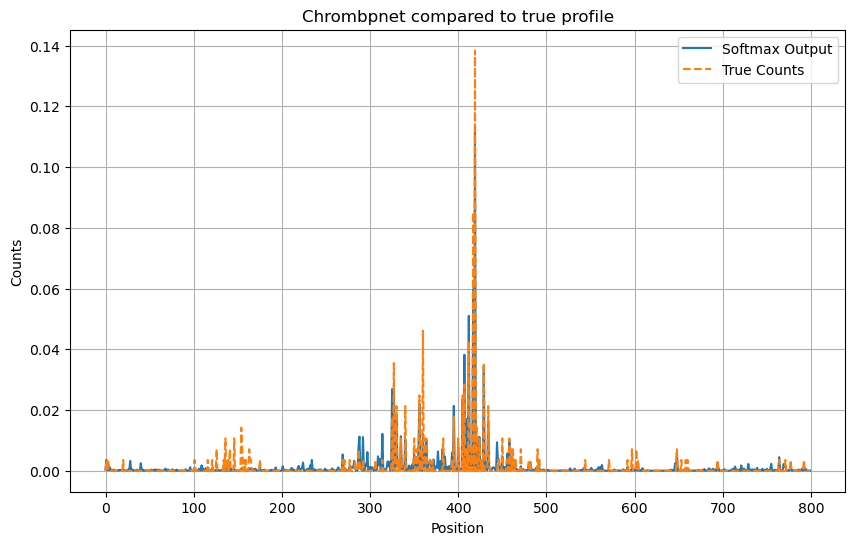

In [44]:
soft_out_np = soft_out.cpu().detach().numpy()
true_counts_np = temp_true_counts

# Create the plot
plt.figure(figsize=(10, 6))

# Plot each series with a label
soft_out_np = soft_out_np / soft_out_np.sum()
plt.plot(soft_out_np, label='Softmax Output', )
true_counts_np = true_counts_np / true_counts_np.sum()
plt.plot(true_counts_np, label='True Counts', linestyle='--')

# Add a legend
plt.legend(loc='best')

# Add axis labels and a title
plt.xlabel('Position')
plt.ylabel('Counts')
plt.title('Chrombpnet compared to true profile')

# Add grid for better readability
plt.grid(True)

(800,)
torch.Size([800])
(26172, 800)


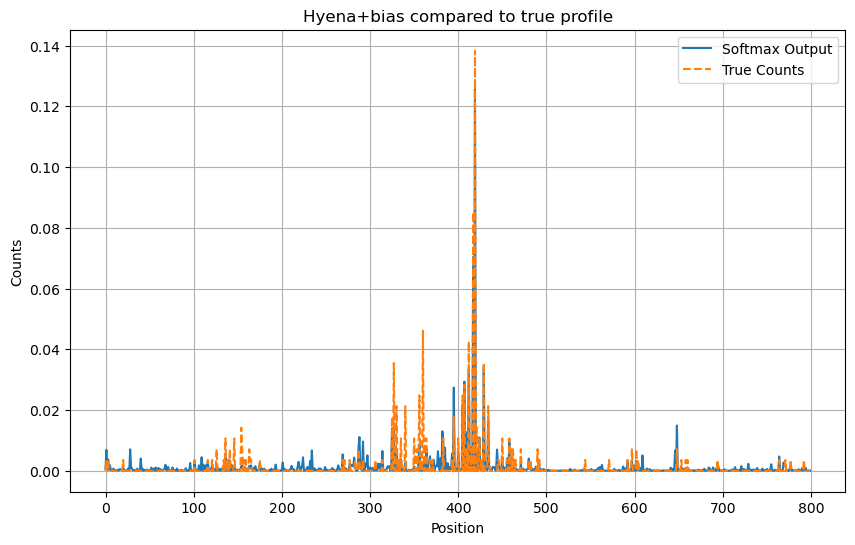

In [48]:
#let's plot an example profile again
#let's look at the profile output
profile_out = bias['profile'][0]
print(profile_out.shape)
#now we take the softmax
soft_out = torch.tensor(profile_out).softmax(dim=0)
print(soft_out.shape)

print(true_profiles.shape)
temp_true_counts = true_profiles[0]
soft_out_np = soft_out.cpu().detach().numpy()
true_counts_np = temp_true_counts

# Create the plot
plt.figure(figsize=(10, 6))

# Plot each series with a label
soft_out_np = soft_out_np / soft_out_np.sum()
plt.plot(soft_out_np, label='Softmax Output', )
true_counts_np = true_counts_np / true_counts_np.sum()
plt.plot(true_counts_np, label='True Counts', linestyle='--')

# Add a legend
plt.legend(loc='best')

# Add axis labels and a title
plt.xlabel('Position')
plt.ylabel('Counts')
plt.title('Hyena+bias compared to true profile')

# Add grid for better readability
plt.grid(True)

(800,)
torch.Size([800])
(26172, 800)


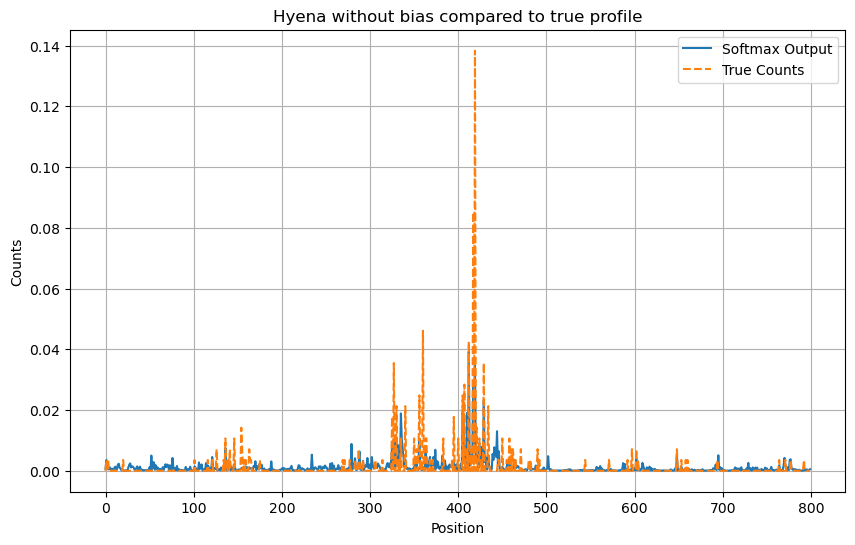

In [49]:
#let's plot an example profile again
#let's look at the profile output
profile_out = nobias['profile'][0]
print(profile_out.shape)
#now we take the softmax
soft_out = torch.tensor(profile_out).softmax(dim=0)
print(soft_out.shape)

print(true_profiles.shape)
temp_true_counts = true_profiles[0]
soft_out_np = soft_out.cpu().detach().numpy()
true_counts_np = temp_true_counts

# Create the plot
plt.figure(figsize=(10, 6))

# Plot each series with a label
soft_out_np = soft_out_np / soft_out_np.sum()
plt.plot(soft_out_np, label='Softmax Output', )
true_counts_np = true_counts_np / true_counts_np.sum()
plt.plot(true_counts_np, label='True Counts', linestyle='--')

# Add a legend
plt.legend(loc='best')

# Add axis labels and a title
plt.xlabel('Position')
plt.ylabel('Counts')
plt.title('Hyena without bias compared to true profile')

# Add grid for better readability
plt.grid(True)

In [53]:
#now let's do a basic correlation, start with 
#now we can do the correlation
from scipy.stats import pearsonr
from tqdm import tqdm
corr_values = np.zeros((bias['profile'].shape[0], 3))
for i in tqdm(range(bias['profile'].shape[0])):
    corr_values[i,0] = pearsonr(bias['profile'][i], true_profiles[i])[0]
    corr_values[i,1] = pearsonr(nobias['profile'][i], true_profiles[i])[0]
    corr_values[i,2] = pearsonr(chbpnet['profile'][i], true_profiles[i])[0]
    if i == 10:
        break

  0%|          | 10/26172 [00:35<26:03:28,  3.59s/it]


In [54]:
print(corr_values[:10,:])

[[0.34169698 0.32362457 0.35487771]
 [0.39171035 0.36127105 0.38240881]
 [0.47076105 0.44267817 0.49355279]
 [0.47033431 0.38219301 0.47081611]
 [0.4457012  0.38475371 0.45957419]
 [0.5092814  0.38712972 0.51860972]
 [0.49090809 0.36366194 0.50375073]
 [0.44249225 0.36255537 0.44697109]
 [0.48767036 0.39658691 0.48696791]
 [0.50165985 0.40106109 0.5025564 ]]


In [56]:
#let's just create a function to calculate pairwise correlations

def pearsonr2(x, y):
    # Compute Pearson correlation coefficient. We can't use `cov` or `corrcoef`
    # because they want to compute everything pairwise between rows of a
    # stacked x and y.
    xm = x.mean(axis=-1, keepdims=True)
    ym = y.mean(axis=-1, keepdims=True)
    cov = np.sum((x - xm) * (y - ym), axis=-1)/(x.shape[-1]-1)
    sx = np.std(x, ddof=1, axis=-1)
    sy = np.std(y, ddof=1, axis=-1)
    rho = cov/(sx * sy)

    return rho

x = bias['profile'][:10]
y = true_profiles[:10]
test_out = pearsonr2(x,y)
print(test_out)


[0.34169698 0.39171035 0.47076105 0.47033431 0.4457012  0.5092814
 0.49090809 0.44249225 0.48767036 0.50165985]


In [58]:
np.allclose(test_out, corr_values[:10,0])

True

In [59]:
#now test this function on the whole thing
def pearsonr2(x, y):
    # Compute Pearson correlation coefficient. We can't use `cov` or `corrcoef`
    # because they want to compute everything pairwise between rows of a
    # stacked x and y.
    xm = x.mean(axis=-1, keepdims=True)
    ym = y.mean(axis=-1, keepdims=True)
    cov = np.sum((x - xm) * (y - ym), axis=-1)/(x.shape[-1]-1)
    sx = np.std(x, ddof=1, axis=-1)
    sy = np.std(y, ddof=1, axis=-1)
    rho = cov/(sx * sy)

    return rho
cbpnet_results = pearsonr2(chbpnet['profile'], true_profiles)
print('done 1')
bias_hyena = pearsonr2(bias['profile'], true_profiles)
print('done2')
nobias_hyena = pearsonr2(nobias['profile'], true_profiles)

#so fast!!!

done 1
done2


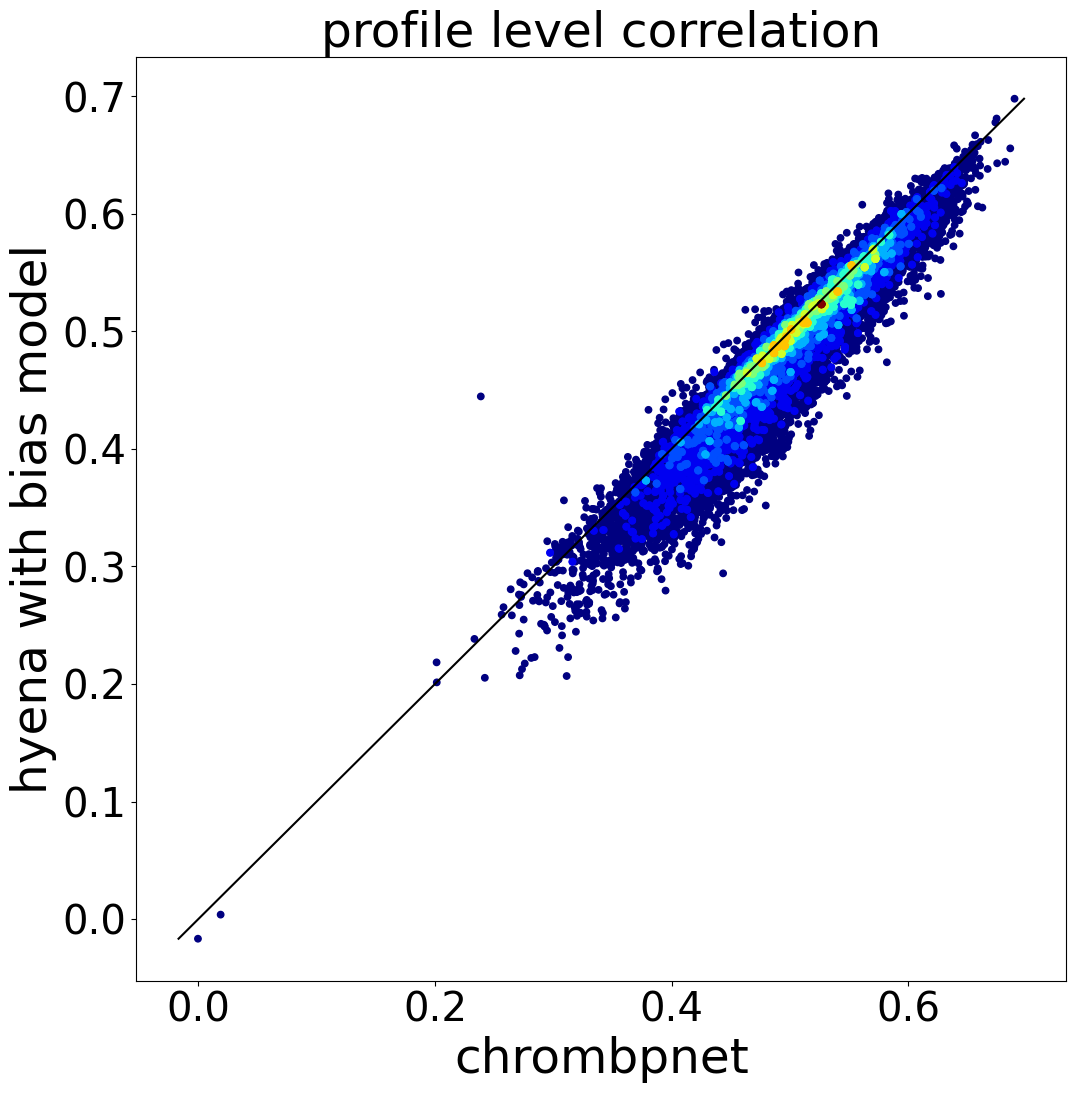

In [60]:
#now let's do the plot

import matplotlib.pyplot as plt
x,y = cbpnet_results, bias_hyena
bins = [1000, 1000] # number of bins

# histogram the data
hh, locx, locy = np.histogram2d(x, y, bins=bins)

# Sort the points by density, so that the densest points are plotted last
z = np.array([hh[np.argmax(a<=locx[1:]),np.argmax(b<=locy[1:])] for a,b in zip(x,y)])
idx = z.argsort()
x2, y2, z2 = x[idx], y[idx], z[idx]

tempmin = np.min([np.min(x), np.min(y)])
tempmax = np.max([np.max(x), np.max(y)])

plt.figure(1,figsize=(12,12)).clf()
s = plt.scatter(x2, y2, c=z2, cmap='jet', marker='.', s = 85)
plt.plot([tempmin, tempmax], [tempmin, tempmax], c='k')  
# plt.colorbar()
plt.xlabel('chrombpnet', fontsize=35)
plt.ylabel('hyena with bias model', fontsize=35)
plt.title('profile level correlation', fontsize=35)
plt.tick_params(labelsize=29)

Text(0.5, 1.0, 'Profile Level Correlation')

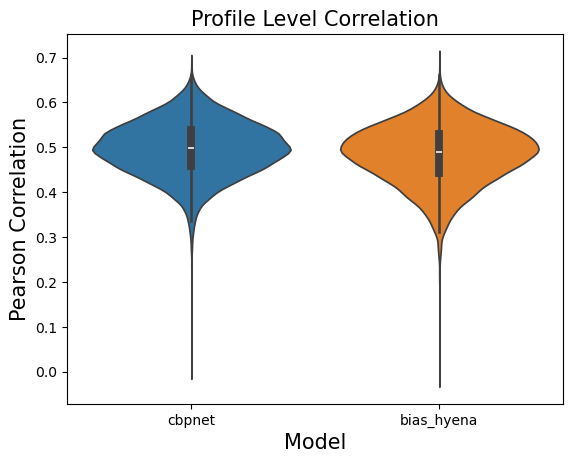

In [62]:
x,y = cbpnet_results, bias_hyena
#do a violin plot
import seaborn as sns
import pandas as pd
df = pd.DataFrame(data={'cbpnet':x, 'bias_hyena':y})
sns.violinplot(data=df)
plt.xlabel('Model', fontsize=15)
plt.ylabel('Pearson Correlation', fontsize=15)
plt.title('Profile Level Correlation', fontsize=15)

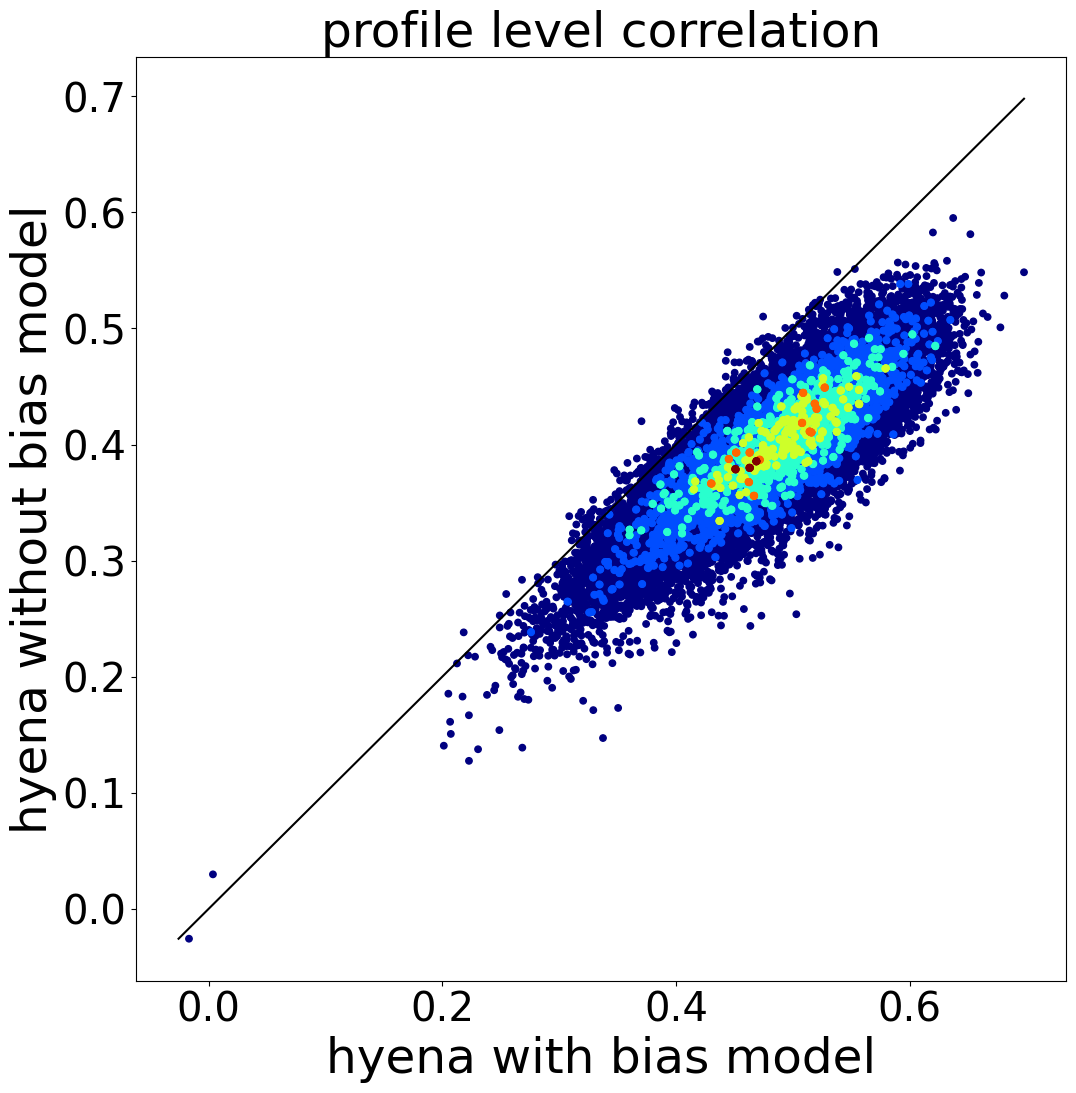

In [61]:
#now let's do the plot

import matplotlib.pyplot as plt
x,y = bias_hyena, nobias_hyena
bins = [1000, 1000] # number of bins

# histogram the data
hh, locx, locy = np.histogram2d(x, y, bins=bins)

# Sort the points by density, so that the densest points are plotted last
z = np.array([hh[np.argmax(a<=locx[1:]),np.argmax(b<=locy[1:])] for a,b in zip(x,y)])
idx = z.argsort()
x2, y2, z2 = x[idx], y[idx], z[idx]

tempmin = np.min([np.min(x), np.min(y)])
tempmax = np.max([np.max(x), np.max(y)])

plt.figure(1,figsize=(12,12)).clf()
s = plt.scatter(x2, y2, c=z2, cmap='jet', marker='.', s = 85)
plt.plot([tempmin, tempmax], [tempmin, tempmax], c='k')  
# plt.colorbar()
plt.xlabel('hyena with bias model', fontsize=35)
plt.ylabel('hyena without bias model', fontsize=35)
plt.title('profile level correlation', fontsize=35)
plt.tick_params(labelsize=29)

In [4]:
true['profile'].shape

(26172, 800)

In [42]:
#let's softmax the data
import torch
# soft_out = torch.tensor(true['profile']).softmax(dim=1)
soft_out = torch.tensor(true['profile'])
print(soft_out.shape)
print(soft_out.sum(dim=1))
print(soft_out.sum(dim=1).shape)
soft_chbpnet = torch.tensor(chbpnet['profile']).softmax(dim=1)
soft_bias = torch.tensor(bias['profile']).softmax(dim=1)
soft_nobias = torch.tensor(nobias['profile']).softmax(dim=1)

torch.Size([26172, 800])
tensor([ 282.,  238.,  293.,  ...,  994., 1373., 1325.], dtype=torch.float64)
torch.Size([26172])


In [43]:
#we can also do it with sofmaxed
true_profiles = true['profile']
#now test this function on the whole thing
def pearsonr2(x, y):
    # Compute Pearson correlation coefficient. We can't use `cov` or `corrcoef`
    # because they want to compute everything pairwise between rows of a
    # stacked x and y.
    xm = x.mean(axis=-1, keepdims=True)
    ym = y.mean(axis=-1, keepdims=True)
    cov = np.sum((x - xm) * (y - ym), axis=-1)/(x.shape[-1]-1)
    sx = np.std(x, ddof=1, axis=-1)
    sy = np.std(y, ddof=1, axis=-1)
    rho = cov/(sx * sy)

    return rho
cbpnet_results = pearsonr2(soft_chbpnet.numpy(), soft_out.numpy())
print('done 1')
bias_hyena = pearsonr2(soft_bias.numpy(), soft_out.numpy())
print('done2')
nobias_hyena = pearsonr2(soft_nobias.numpy(), soft_out.numpy())

#so fast!!!

done 1
done2


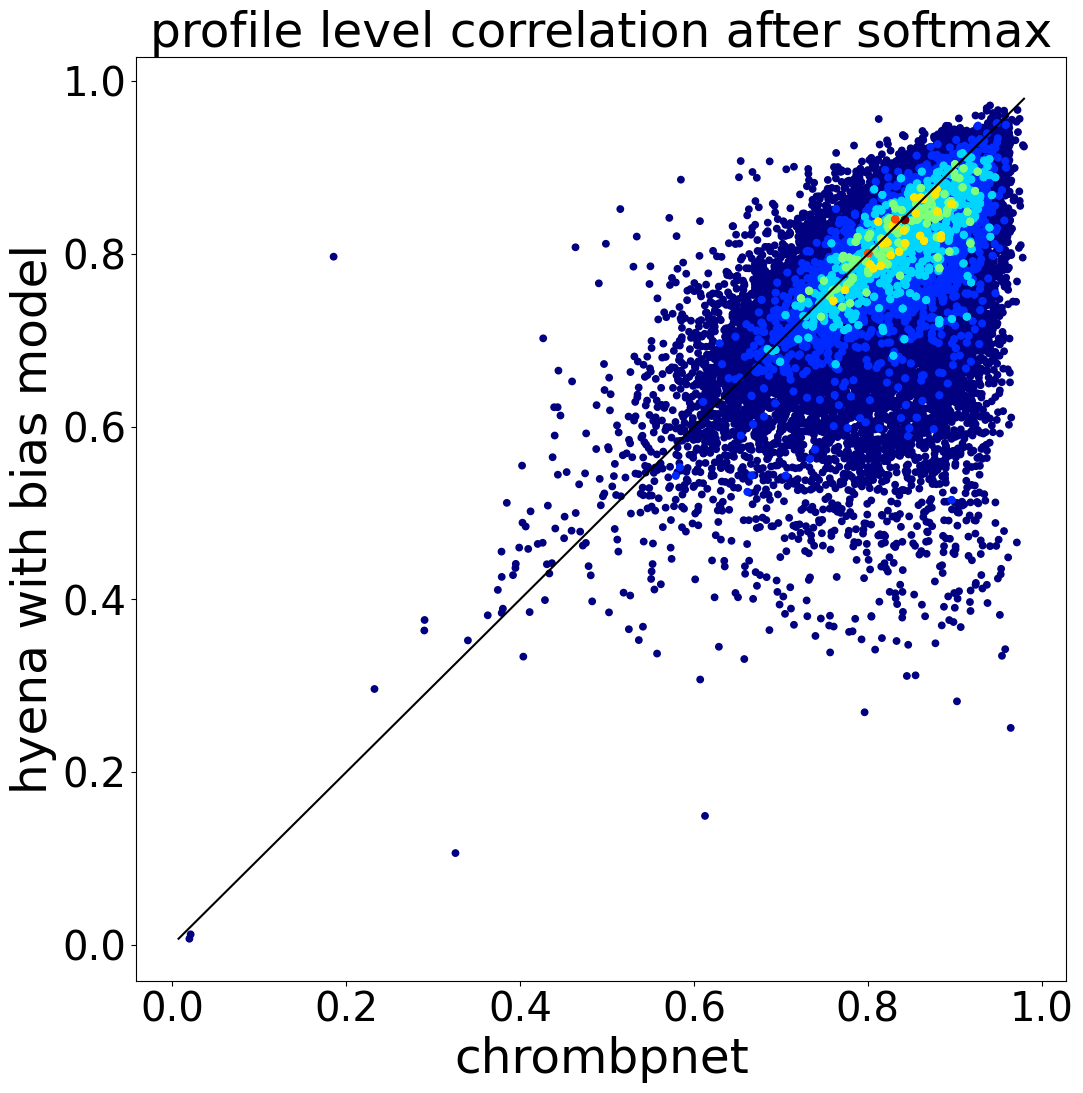

In [44]:
#now let's do the plot

import matplotlib.pyplot as plt
x,y = cbpnet_results, bias_hyena
bins = [1000, 1000] # number of bins

# histogram the data
hh, locx, locy = np.histogram2d(x, y, bins=bins)

# Sort the points by density, so that the densest points are plotted last
z = np.array([hh[np.argmax(a<=locx[1:]),np.argmax(b<=locy[1:])] for a,b in zip(x,y)])
idx = z.argsort()
x2, y2, z2 = x[idx], y[idx], z[idx]

tempmin = np.min([np.min(x), np.min(y)])
tempmax = np.max([np.max(x), np.max(y)])

plt.figure(1,figsize=(12,12)).clf()
s = plt.scatter(x2, y2, c=z2, cmap='jet', marker='.', s = 85)
plt.plot([tempmin, tempmax], [tempmin, tempmax], c='k')  
# plt.colorbar()
plt.xlabel('chrombpnet', fontsize=35)
plt.ylabel('hyena with bias model', fontsize=35)
plt.title('profile level correlation after softmax', fontsize=35)
plt.tick_params(labelsize=29)

Text(0.5, 1.0, 'Profile Level Correlation')

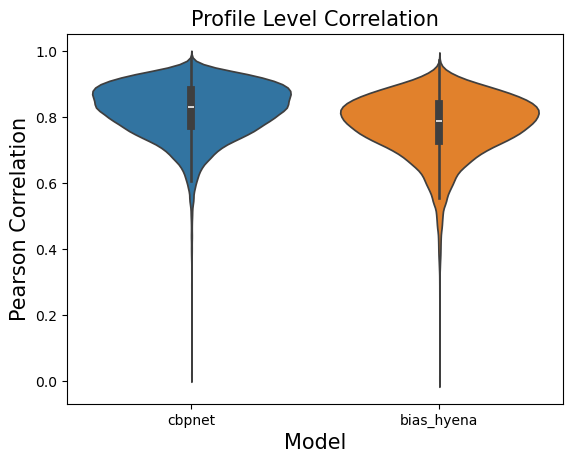

In [45]:
x,y = cbpnet_results, bias_hyena
#do a violin plot
import seaborn as sns
import pandas as pd
df = pd.DataFrame(data={'cbpnet':x, 'bias_hyena':y})
sns.violinplot(data=df)
plt.xlabel('Model', fontsize=15)
plt.ylabel('Pearson Correlation', fontsize=15)
plt.title('Profile Level Correlation', fontsize=15)

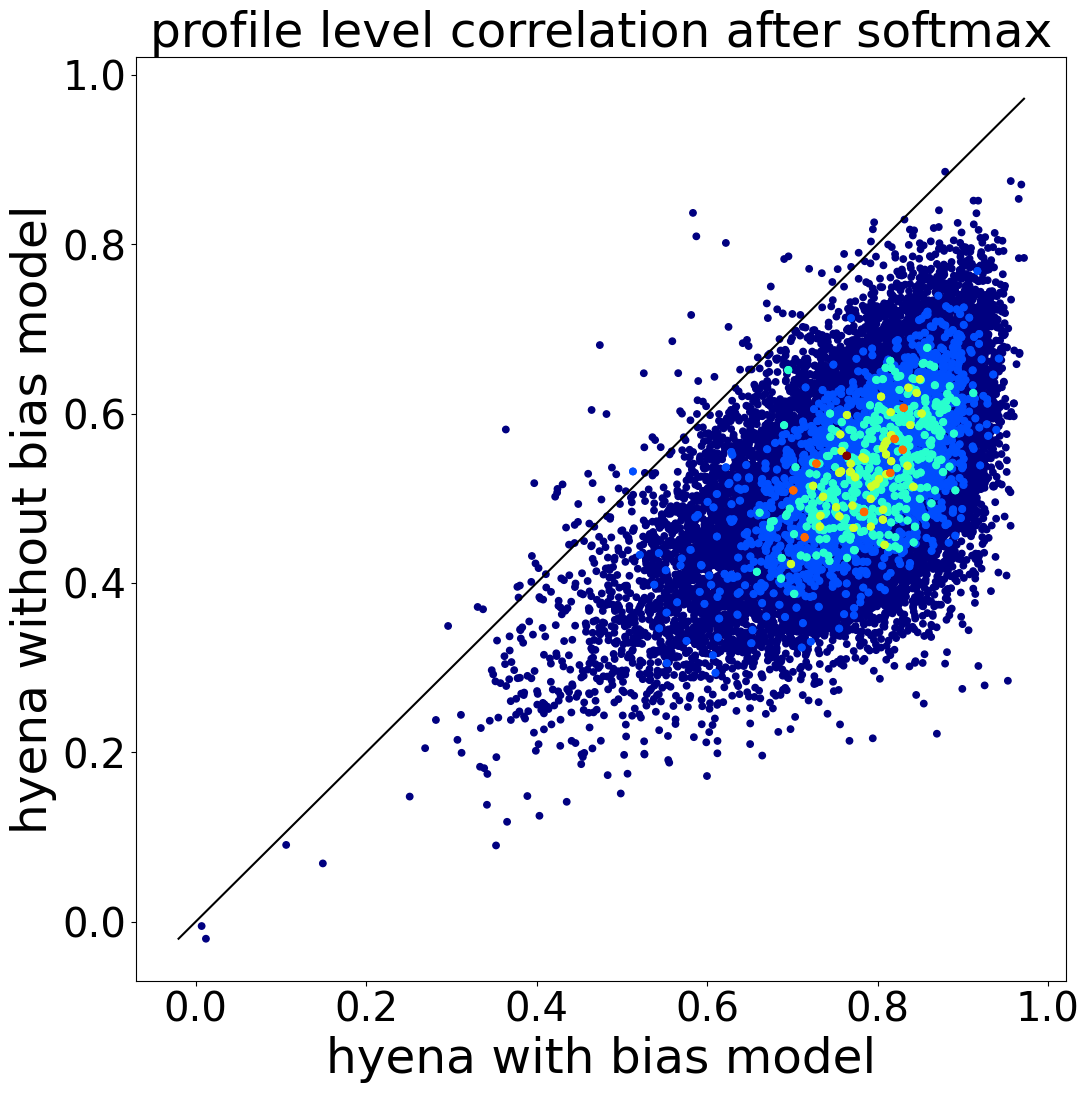

In [46]:
#now let's do the plot

import matplotlib.pyplot as plt
x,y = bias_hyena, nobias_hyena
bins = [1000, 1000] # number of bins

# histogram the data
hh, locx, locy = np.histogram2d(x, y, bins=bins)

# Sort the points by density, so that the densest points are plotted last
z = np.array([hh[np.argmax(a<=locx[1:]),np.argmax(b<=locy[1:])] for a,b in zip(x,y)])
idx = z.argsort()
x2, y2, z2 = x[idx], y[idx], z[idx]

tempmin = np.min([np.min(x), np.min(y)])
tempmax = np.max([np.max(x), np.max(y)])

plt.figure(1,figsize=(12,12)).clf()
s = plt.scatter(x2, y2, c=z2, cmap='jet', marker='.', s = 85)
plt.plot([tempmin, tempmax], [tempmin, tempmax], c='k')  
# plt.colorbar()
plt.xlabel('hyena with bias model', fontsize=35)
plt.ylabel('hyena without bias model', fontsize=35)
plt.title('profile level correlation after softmax', fontsize=35)
plt.tick_params(labelsize=29)

# predicting on validation data (includes negatives)

In [4]:
#first we modified the eval_utils.py file to include the pearsonr2 function and also to do this for the profile level models
#first let's test our eval utils
import sys
sys.path.append('/data/leslie/sarthak/hyena/hyena-dna/')
from evals.evals_utils import *
import numpy as np
import torch

#now let's load in the data
ckpt_path = '/data/leslie/sarthak/hyena/hyena-dna/outputs/2024-06-15/07-29-09-511172/checkpoints/86-val_loss=887.93817.ckpt'
bias_model_path = '/data/leslie/sarthak/data/chrombpnet_test/chrombpnet_model_1000/models/bias_model_scaled.h5'
util = Evals('Profile',ckpt_path, bias=bias_model_path)

In [7]:
util.decoder #yes it works!

ProfileDecoder(
  (output_transform_counts): Linear(in_features=128, out_features=1, bias=True)
  (output_transform_profile): Linear(in_features=128, out_features=1, bias=True)
)

In [11]:
len(util.dataset)

26172

In [26]:
num_workers = 0
batch_size = 128
targets_profile = torch.zeros((len(util.dataset), util.profile_len))
targets_counts = torch.zeros((len(util.dataset)))
predicts_profile = torch.zeros((len(util.dataset), util.profile_len))
predicts_counts = torch.zeros((len(util.dataset)))
loader = DataLoader(util.dataset, batch_size=batch_size, shuffle=False, num_workers=num_workers)
with torch.no_grad():
    idx = 0
    for i, batch in tqdm(enumerate(loader), total = len(loader)):
        (seq, seq_onehot), (profile,counts) = batch
        seq = seq.to(util.device)
        b_size = seq.shape[0]
        y_hat, _ = util.backbone(seq)
        y_hat = util.decoder(y_hat)
        if y_hat[0].shape[1] > profile.shape[1]:
            #then we cut off from both ends until we get the same size
            diff = y_hat[0].shape[1] - profile.shape[1]
            start = diff // 2
            end = start + profile.shape[1]
            profile_out = y_hat[0][:, start:end].squeeze()
        if util.bias:
            bias_out = util.model(seq_onehot.to(util.device))
            profile_out = profile_out + bias_out[0].squeeze()
            counts_out = torch.logsumexp(torch.cat([y_hat[1], bias_out[1]], dim=1), dim=1, keepdim=True)
        targets_profile[idx:b_size+idx,:] = profile.squeeze().cpu()
        targets_counts[idx:b_size+idx] = counts.squeeze().cpu()
        predicts_profile[idx:b_size+idx,:] = profile_out.detach().cpu()
        predicts_counts[idx:b_size+idx] = counts_out.detach().cpu().squeeze()
        idx += b_size

100%|██████████| 205/205 [00:43<00:00,  4.70it/s]


In [20]:
sys.path.append('/data/leslie/sarthak/chrombpnet/')
from bpnetlite.bpnet import BPNet
#the location is /data/leslie/sarthak/chrombpnet/bpnetlite/bpnet.py
model = BPNet.from_chrombpnet(util.bias,trimming=(1024-800)//2)
#eval mode and move it
util.model = model.eval().to(util.device)
util.model

BPNet(
  (iconv): Conv1d(4, 128, kernel_size=(21,), stride=(1,), padding=(10,))
  (irelu): ReLU()
  (rconvs): ModuleList(
    (0): Conv1d(128, 128, kernel_size=(3,), stride=(1,), padding=(2,), dilation=(2,))
    (1): Conv1d(128, 128, kernel_size=(3,), stride=(1,), padding=(4,), dilation=(4,))
    (2): Conv1d(128, 128, kernel_size=(3,), stride=(1,), padding=(8,), dilation=(8,))
    (3): Conv1d(128, 128, kernel_size=(3,), stride=(1,), padding=(16,), dilation=(16,))
  )
  (rrelus): ModuleList(
    (0-3): 4 x ReLU()
  )
  (fconv): Conv1d(128, 1, kernel_size=(75,), stride=(1,), padding=(37,))
  (linear): Linear(in_features=128, out_features=1, bias=True)
)

In [14]:
len(batch)

2

In [16]:
len(batch[1])

2

In [23]:
profile_out.shape

torch.Size([128, 128, 800])

In [24]:
y_hat[0][:, start:end].squeeze().shape


torch.Size([128, 800])

In [25]:
bias_out[0].shape

torch.Size([128, 1, 800])

In [27]:
predicts_profile.shape

torch.Size([26172, 800])

In [28]:
#now let's quickly check if all are the same!

predicts_profile = predicts_profile.numpy()
predicts_counts = predicts_counts.numpy()
targets_profile = targets_profile.numpy()
targets_counts = targets_counts.numpy()

In [29]:
#now load in the other ones
bias = np.load('/data/leslie/sarthak/data/chrombpnet_test/saved_data_1000/profile_bias.npz')
targets = np.load('/data/leslie/sarthak/data/chrombpnet_test/saved_data_1000/true_data.npz')

In [37]:
#now we compare them
print(np.allclose(predicts_profile, bias['profile'], atol=1e-2))
print(np.allclose(predicts_counts, bias['counts']))

True
False


In [31]:
predicts_profile

array([[18.65642 , 21.107422, 17.90487 , ..., 14.276436, 15.661356,
        15.809014],
       [18.657421, 18.089645, 20.506176, ..., 17.259779, 15.539204,
        18.41584 ],
       [20.466673, 21.29318 , 15.811835, ..., 16.740772, 13.092904,
        16.174492],
       ...,
       [19.758806, 19.637253, 18.13244 , ..., 22.798779, 19.767332,
        22.058573],
       [15.513187, 19.304157, 21.593525, ..., 20.236048, 18.227806,
        20.267124],
       [19.511616, 18.071793, 16.983482, ..., 18.687134, 16.23391 ,
        20.17772 ]], dtype=float32)

In [32]:
bias['profile']

array([[18.6557045 , 21.10790825, 17.90480614, ..., 14.27645206,
        15.66130924, 15.80887985],
       [18.65724564, 18.08888626, 20.50635338, ..., 17.26049614,
        15.53781891, 18.4166317 ],
       [20.46700668, 21.29360199, 15.81075954, ..., 16.74096489,
        13.09121609, 16.17450333],
       ...,
       [19.75917435, 19.6374836 , 18.13212013, ..., 22.79925919,
        19.76750565, 22.05871773],
       [15.51235962, 19.30398941, 21.59496307, ..., 20.23680878,
        18.22748375, 20.26708031],
       [19.51170349, 18.07102776, 16.98255157, ..., 18.68727684,
        16.23332214, 20.178339  ]])

In [35]:
#check if we are in eval mode
print(util.model.training, util.backbone.training, util.decoder.training) #so all are in eval mode, hmmm...

False False False


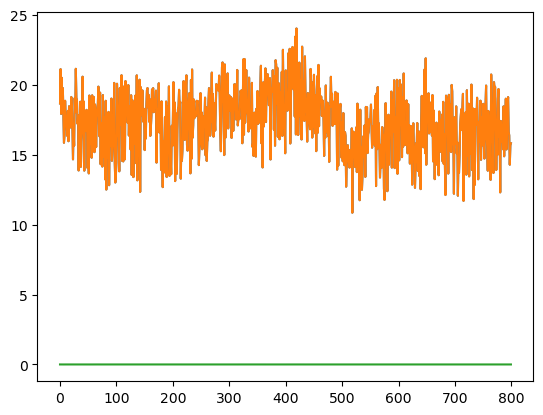

In [42]:
import matplotlib.pyplot as plt
plt.plot(predicts_profile[0], label='Predicted Profile')
plt.plot(bias['profile'][0], label='Bias Profile')
plt.plot(predicts_profile[0]-bias['profile'][0], label='Difference')

In [ ]:
plt.plot(targets_profile[0], label='True Profile')


In [43]:
print((predicts_profile-bias['profile']).max())

0.00414276123046875


In [46]:
#I think this is actually just gpu differences, but let's retest by redoing this

#restarted the kernel, now we can do the same thing but we want to use the bias model one this time
import torch
import sys
sys.path.append('/data/leslie/sarthak/hyena/hyena-dna/')
from src.dataloaders.datasets.hg38_char_tokenizer import CharacterTokenizer
from src.models.sequence.dna_embedding import DNAEmbeddingModel
from torch.utils.data import DataLoader
from src.tasks.decoders import ProfileDecoder
import yaml

tokenizer = CharacterTokenizer( #make sure to fix the tokenizer too
    characters=['A', 'C', 'G', 'T', 'N'],
    model_max_length=1024 + 2,  # add 2 since default adds eos/eos tokens, crop later
    add_special_tokens=False,
    padding_side='left'
)

cfg = '/data/leslie/sarthak/hyena/hyena-dna/configs/evals/profile.yaml'
cfg = yaml.load(open(cfg, 'r'), Loader=yaml.FullLoader)
train_cfg = cfg['train']  # grab section `train` section of config
model_cfg = cfg['model_config']  # grab the `model` section of config
d_output = train_cfg['d_output']  #TODO make it so that we just adjust this with self.classificaiton, no need for evals
# print(d_output, model_cfg, train_cfg)
backbone = DNAEmbeddingModel(**model_cfg)
decoder = ProfileDecoder(model_cfg['d_model'], d_output=d_output, l_output=0, mode='pool')
ckpt_path = '/data/leslie/sarthak/hyena/hyena-dna/outputs/2024-06-15/07-29-09-511172/checkpoints/86-val_loss=887.93817.ckpt'
bias_model_path = '/data/leslie/sarthak/data/chrombpnet_test/chrombpnet_model_1000/models/bias_model_scaled.h5'

state_dict = torch.load(ckpt_path, map_location='cpu')

backbone = DNAEmbeddingModel(**model_cfg)
decoder = ProfileDecoder(model_cfg['d_model'], d_output=d_output, l_output=0, mode='pool')
state_dict = torch.load(ckpt_path, map_location='cpu')

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.nn.modules.utils.consume_prefix_in_state_dict_if_present(
    state_dict["state_dict"], "model."
)
model_state_dict = state_dict["state_dict"]
# need to remove torchmetrics. to remove keys, need to convert to list first
for key in list(model_state_dict.keys()):
    if "torchmetrics" in key:
        model_state_dict.pop(key)
# the state_dict keys slightly mismatch from Lightning..., so we fix it here
decoder_state_dict = {}
decoder_state_dict['output_transform_counts.weight'] = model_state_dict.pop('decoder.0.output_transform_counts.weight')
decoder_state_dict['output_transform_counts.bias'] = model_state_dict.pop('decoder.0.output_transform_counts.bias')
decoder_state_dict['output_transform_profile.weight'] = model_state_dict.pop('decoder.0.output_transform_profile.weight')
decoder_state_dict['output_transform_profile.bias'] = model_state_dict.pop('decoder.0.output_transform_profile.bias')
# now actually load the state dict to the decoder and backbone separately
decoder.load_state_dict(decoder_state_dict, strict=True)
backbone.load_state_dict(model_state_dict, strict=True)
decoder = decoder.to(device).eval()
backbone = backbone.to(device).eval()
#now we load in the bias model

#let's plot an output with and without the bias, see how much the model actually adds to it...

bias_model_path = '/data/leslie/sarthak/data/chrombpnet_test/chrombpnet_model_1000/models/bias_model_scaled.h5'
#load it
import sys
sys.path.append('/data/leslie/sarthak/chrombpnet/')
from bpnetlite.bpnet import BPNet
#the location is /data/leslie/sarthak/chrombpnet/bpnetlite/bpnet.py
model = BPNet.from_chrombpnet(bias_model_path,trimming=(1024-800)//2)
#eval mode and move it
model.eval().to(device)
#now let's look at an example
from src.dataloaders.datasets.profile_atac import ProfileATAC
dataset = ProfileATAC(max_length = 1024, split = 'test', tokenizer=tokenizer, rc_aug = False, tokenizer_name='char', add_eos='False')


In [47]:
#let's now go through and save out the results
from tqdm import tqdm
import numpy as np
counts_matrix = np.zeros((len(dataset)))
profile_matrix = np.zeros((len(dataset), 800))
print(counts_matrix.shape, profile_matrix.shape)
for i in tqdm(range(len(dataset))):
    out1 = backbone(dataset[i][0][0].unsqueeze(0).to(device))
    out2 = decoder(out1[0])
    true_counts = dataset[i][1][0].unsqueeze(0).to(device)
    if out2[0].shape[1] > true_counts.shape[1]:
        #then we cut off from both ends until we get the same size
        diff = out2[0].shape[1] - true_counts.shape[1]
        start = diff // 2
        end = start + true_counts.shape[1]
        profile_out = out2[0][:, start:end].squeeze()
    bias_out = model(dataset[i][0][1].unsqueeze(0).to(device))
    combined_out = profile_out + bias_out[0].squeeze()
    counts_out = torch.logsumexp(torch.cat([out2[1], bias_out[1]], dim=1), dim=1, keepdim=True)
    counts_matrix[i] = counts_out.item()
    profile_matrix[i] = combined_out.cpu().detach().numpy()
    # print(combined_out.shape, profile_out.shape, bias_out[0].shape)
    # print(counts_out.shape, out2[1].shape, bias_out[1].shape)

(26172,) (26172, 800)


100%|██████████| 26172/26172 [03:46<00:00, 115.69it/s]


In [49]:
#now check if these are close
print(np.allclose(profile_matrix, predicts_profile, atol=1e-6)) #yeah it's just gpu differences, but our eval utils works!!

True


# eval utils on validation data

In [1]:
#first we modified the eval_utils.py file to include the pearsonr2 function and also to do this for the profile level models
#first let's test our eval utils
import sys
sys.path.append('/data/leslie/sarthak/hyena/hyena-dna/')
from evals.evals_utils import *
import numpy as np
import torch

#now let's load in the data
ckpt_path = '/data/leslie/sarthak/hyena/hyena-dna/outputs/2024-06-15/07-29-09-511172/checkpoints/86-val_loss=887.93817.ckpt'
bias_model_path = '/data/leslie/sarthak/data/chrombpnet_test/chrombpnet_model_1000/models/bias_model_scaled.h5'
util = Evals('Profile',ckpt_path, bias=bias_model_path, split='valid')

In [4]:
util.model is None

True

In [6]:
util.bias is not None #oh fixed the bug

True

In [5]:
target,predicts = util.evaluate(128,0)

100%|██████████| 200/200 [00:43<00:00,  4.62it/s]


In [4]:
split='train'
data_path = f'/data/leslie/sarthak/data/chrombpnet_test/saved_data_1000/{split}/'
peak_seqs = np.load(data_path+'peak_seqs.npy')
print(peak_seqs.shape)
split = 'valid'
data_path = f'/data/leslie/sarthak/data/chrombpnet_test/saved_data_1000/{split}/'
peak_seqs = np.load(data_path+'peak_seqs.npy')
print(peak_seqs.shape)
split='test'
data_path = f'/data/leslie/sarthak/data/chrombpnet_test/saved_data_1000/{split}/'
peak_seqs = np.load(data_path+'peak_seqs.npy')
print(peak_seqs.shape)

(220311, 2024, 4)
(23208, 1024, 4)
(26172, 1024, 4)


In [3]:
len(util.dataset) #should be 10% longer because of the negatives! and indeed it is!

25528

In [9]:
predicts[0][0].shape

torch.Size([800])

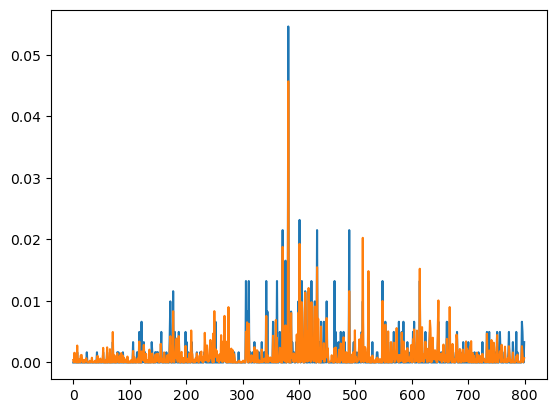

In [13]:
#now let's take a look at the results compared to the true data
import matplotlib.pyplot as plt
plt.plot(target[0][0]/target[0][0].sum(), label='True Profile')
plt.plot(predicts[0][0].softmax(dim=0), label='Predicted Profile')
#yeah it's actually quite decent!

In [14]:
target[0].shape

torch.Size([25528, 800])

In [15]:
#let's save out the results
import numpy as np
np.savez_compressed('/data/leslie/sarthak/data/chrombpnet_test/saved_data_1000/profile_bias_val.npz', counts=predicts[1].numpy(), profile=predicts[0].numpy())
np.savez_compressed('/data/leslie/sarthak/data/chrombpnet_test/saved_data_1000/true_data_val.npz', counts=target[1].numpy(), profile=target[0].numpy())

In [16]:
predicts[0].numpy().shape

(25528, 800)

In [18]:
print(target[1][-1])
print(predicts[1][-1]) #;yeah it's quite off...

tensor(2.0794)
tensor(4.6705)


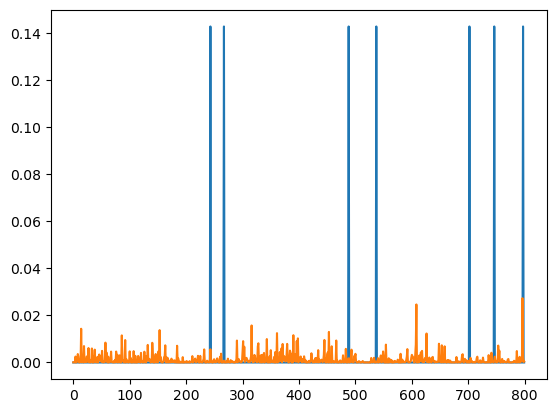

In [17]:
#let's look at a negative
import matplotlib.pyplot as plt
plt.plot(target[0][-1]/target[0][-1].sum(), label='True Profile')
plt.plot(predicts[0][-1].softmax(dim=0), label='Predicted Profile')
#this is actually quite bad, 

In [25]:
#now let's test it with chrombpnet, we have to be careful to stick to the same validation set as th enegatives will differ
#let's save out the validation set
util.dataset.one_hot_seq.shape
#save it out
np.save('/data/leslie/sarthak/data/chrombpnet_test/saved_data_1000/valid_seqs.npy', util.dataset.one_hot_seq)

In [26]:
#let's first run it on the nobias model to compare
ckpt_path = '/data/leslie/sarthak/hyena/hyena-dna/outputs/2024-06-15/07-49-23-830590/checkpoints/86-val_loss=1472.48523.ckpt'
util_nobias = Evals('Profile',ckpt_path, split='valid')
util_nobias.dataset = util.dataset
util_nobias.bias #should be none...

In [27]:
util_nobias.bias is None

True

In [33]:
if None:
    print('yes')

In [28]:
#now let's evaluate it
target_nobias,predicts_nobias = util_nobias.evaluate(128,0)

  0%|          | 0/200 [00:00<?, ?it/s]


UnboundLocalError: cannot access local variable 'counts_out' where it is not associated with a value

In [30]:
batch_size = 128
num_workers = 0
targets_profile = torch.zeros((len(util_nobias.dataset), util_nobias.profile_len))
targets_counts = torch.zeros((len(util_nobias.dataset)))
predicts_profile = torch.zeros((len(util_nobias.dataset), util_nobias.profile_len))
predicts_counts = torch.zeros((len(util_nobias.dataset)))
loader = DataLoader(util_nobias.dataset, batch_size=batch_size, shuffle=False, num_workers=num_workers)
with torch.no_grad():
    idx = 0
    for i, batch in tqdm(enumerate(loader), total = len(loader)):
        (seq, seq_onehot), (profile,counts) = batch
        seq = seq.to(util_nobias.device)
        b_size = seq.shape[0]
        y_hat, _ = util_nobias.backbone(seq)
        y_hat = util_nobias.decoder(y_hat)
        counts_out = y_hat[1]
        if y_hat[0].shape[1] > profile.shape[1]:
            #then we cut off from both ends until we get the same size
            diff = y_hat[0].shape[1] - profile.shape[1]
            start = diff // 2
            end = start + profile.shape[1]
            profile_out = y_hat[0][:, start:end].squeeze()
        if util_nobias.bias:
            bias_out = util_nobias.model(seq_onehot.to(util_nobias.device))
            profile_out = profile_out + bias_out[0].squeeze()
            counts_out = torch.logsumexp(torch.cat([y_hat[1], bias_out[1]], dim=1), dim=1, keepdim=True)
        targets_profile[idx:b_size+idx,:] = profile.squeeze().cpu()
        targets_counts[idx:b_size+idx] = counts.squeeze().cpu()
        predicts_profile[idx:b_size+idx,:] = profile_out.detach().cpu()
        predicts_counts[idx:b_size+idx] = counts_out.detach().cpu().squeeze()
        idx += b_size
targets = (targets_profile, targets_counts)
predicts = (predicts_profile, predicts_counts)

  0%|          | 1/200 [00:00<01:06,  3.00it/s]

100%|██████████| 200/200 [00:45<00:00,  4.38it/s]


In [31]:
#save out these predicts and targets
np.savez_compressed('/data/leslie/sarthak/data/chrombpnet_test/saved_data_1000/profile_nobias_val.npz', counts=predicts[1].numpy(), profile=predicts[0].numpy())

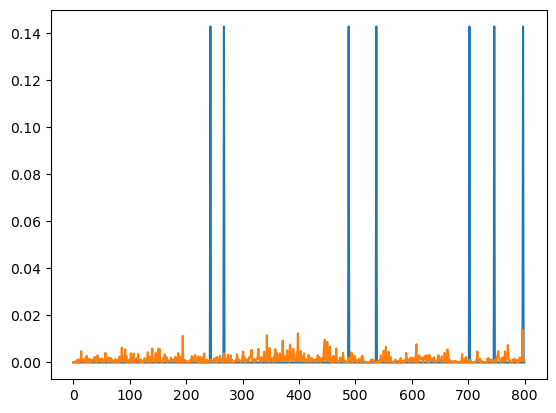

In [32]:
plt.plot(targets[0][-1]/targets[0][-1].sum(), label='True Profile')
plt.plot(predicts[0][-1].softmax(dim=0), label='Predicted Profile')

In [34]:
print(targets[1][-1])
print(predicts[1][-1]) #;yeah it's quite off... even worse on the counts

tensor(2.0794)
tensor(5.8442)


## chrombpnet evaluation on negatives

In [1]:
#final one is chrombpnet...

import argparse
import copy
import sys
sys.path.insert(0,'/data/leslie/sarthak/chrombpnet/')
# print(sys.path)
sys.path.append('/data/leslie/sarthak/chrombpnet/chrombpnet/')
#path of test args
#/data/leslie/sarthak/chrombpnet/chrombpnet/test_args.py
from test_args import main
sys.argv = [
    'test_args.py', 'pipeline',
    '-ibam', '/data/leslie/sarthak/data/chrombpnet_test/merged.bam',
    '-d', 'ATAC',
    '-g', '/data/leslie/sarthak/data/chrombpnet_test/hg38.fa',
    '-c', '/data/leslie/sarthak/data/chrombpnet_test/hg38.chrom.sizes',
    '-p', '/data/leslie/sarthak/data/chrombpnet_test/peaks_no_blacklist.bed',
    '-n', '/data/leslie/sarthak/data/chrombpnet_test/output_negatives.bed',
    '-fl', '/data/leslie/sarthak/data/chrombpnet_test/splits/fold_0.json',
    '-b', '/data/leslie/sarthak/data/chrombpnet_test/bias_model_1000/models/k562_bias.h5',
    '-o', '/data/leslie/sarthak/data/chrombpnet_test/chrombpnet_model/',
    '-il', '1024',
    '-ol', '800'
]
args = main()
#and now we can simulate our args

#now we modify args
import json
import os
if args.file_prefix:
    fpx = args.file_prefix+"_"
else:
    fpx = ""

args.output_prefix = os.path.join(args.output_dir,"auxiliary/{}data".format(fpx))
args.plus_shift = None
args.minus_shift = None
args.bigwig = os.path.join(args.output_dir,"auxiliary/{}data_unstranded.bw".format(fpx))
args.output_prefix = os.path.join(args.output_dir,"evaluation/{}bw_shift_qc".format(fpx))
folds = json.load(open(args.chr_fold_path))
args.chr = folds["valid"][0]
args.pwm_width=24

import chrombpnet.training.predict as predict
args_copy = copy.deepcopy(args)
args_copy.output_prefix = os.path.join(args_copy.output_dir,"evaluation/bias")
args_copy.peaks = os.path.join(args.output_dir,"auxiliary/{}filtered.peaks.bed".format(fpx))
args_copy.model_h5 = args.bias_model_path
args_copy.nonpeaks = "None"
print(args_copy.model_h5)

metrics_dictionary = {"counts_metrics":{}, "profile_metrics":{}}

# get model architecture to load - can load .hdf5 and .weights/.arch
# model=predict.load_model_wrapper(args_copy)
#/data/leslie/sarthak/data/chrombpnet_test/bias_model_1000/models/k562_bias.h5
args_copy.model_h5 = '/data/leslie/sarthak/data/chrombpnet_test/chrombpnet_model_1000/models/chrombpnet.h5'
model = predict.load_model_wrapper(args_copy)

Namespace(cmd='pipeline', genome='/data/leslie/sarthak/data/chrombpnet_test/hg38.fa', chrom_sizes='/data/leslie/sarthak/data/chrombpnet_test/hg38.chrom.sizes', input_bam_file='/data/leslie/sarthak/data/chrombpnet_test/merged.bam', input_fragment_file=None, input_tagalign_file=None, output_dir='/data/leslie/sarthak/data/chrombpnet_test/chrombpnet_model/', data_type='ATAC', peaks='/data/leslie/sarthak/data/chrombpnet_test/peaks_no_blacklist.bed', nonpeaks='/data/leslie/sarthak/data/chrombpnet_test/output_negatives.bed', chr_fold_path='/data/leslie/sarthak/data/chrombpnet_test/splits/fold_0.json', outlier_threshold=0.9999, ATAC_ref_path=None, DNASE_ref_path=None, num_samples=10000, inputlen=1024, outputlen=800, seed=1234, epochs=50, early_stop=5, learning_rate=0.001, trackables=['logcount_predictions_loss', 'loss', 'logits_profile_predictions_loss', 'val_logcount_predictions_loss', 'val_loss', 'val_logits_profile_predictions_loss'], architecture_from_file=None, file_prefix=None, html_pref

2024-06-18 15:46:19.701436: I tensorflow/core/platform/cpu_feature_guard.cc:151] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  SSE4.1 SSE4.2 AVX AVX2 AVX512F FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.
2024-06-18 15:46:21.873010: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1525] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 78963 MB memory:  -> device: 0, name: NVIDIA A100 80GB PCIe, pci bus id: 0000:ca:00.0, compute capability: 8.0
/lila/data/leslie/sarthak/environments/chrombpnet/lib/python3.10/site-packages/keras/layers/core/lambda_layer.py:303: UserWarning:  is not loaded, but a Lambda layer uses it. It may cause errors.
  function = cls._parse_function_from_config(config, custom_objects,


got the model


In [2]:
model.summary()

Model: "model"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 sequence (InputLayer)          [(None, 1024, 4)]    0           []                               
                                                                                                  
 model_wo_bias (Functional)     [(None, 800),        4017154     ['sequence[0][0]']               
                                 (None, 1)]                                                       
                                                                                                  
 model (Functional)             [(None, 800),        217730      ['sequence[0][0]']               
                                 (None, 1)]                                                       
                                                                                              

In [3]:
#load the data first
import numpy as np
seqs = np.load('/data/leslie/sarthak/data/chrombpnet_test/saved_data_1000/valid_seqs.npy')
print(seqs.shape)

(25528, 1024, 4)


In [7]:
out1 = model.predict(seqs[0].reshape(1,1024,4), batch_size=128)
print(out1[0],out1[1])

[[22.018738 19.288944 23.363928 20.522507 19.952826 23.132658 17.356445
  23.920816 19.357798 18.224815 21.742088 22.243849 18.669289 22.8352
  22.982418 22.92416  20.622551 18.366907 19.850925 21.94729  17.639107
  21.824541 21.788876 22.3075   21.158852 18.148043 18.483774 18.882738
  19.610407 21.282629 18.4661   20.9714   20.403286 22.324587 18.461592
  18.658613 19.513615 20.762634 19.840652 21.58184  17.863792 21.161192
  18.032204 22.614042 19.520477 18.268541 20.41064  21.254768 22.155724
  19.197495 19.477224 21.01827  20.243654 23.449203 18.828665 20.3348
  17.382507 16.927584 22.073498 18.948395 23.836441 18.205345 21.227478
  22.338367 18.66539  23.544296 17.256317 18.376816 21.868599 19.000294
  24.247961 19.825027 21.014717 23.09966  17.87784  22.612122 18.61783
  21.699562 23.340145 20.97413  22.65339  17.268461 19.71938  22.743229
  20.605742 22.899426 19.741322 20.82329  22.868246 18.761036 22.429674
  20.41656  22.079456 20.146206 21.80834  18.610659 22.639648 17.1116

In [4]:
out1 = model.predict(seqs[0].reshape(1,1024,4), batch_size=128)
print(out1[0],out1[1])

2024-06-18 15:46:25.156203: I tensorflow/stream_executor/cuda/cuda_dnn.cc:368] Loaded cuDNN version 8907
2024-06-18 15:46:25.931467: W tensorflow/stream_executor/gpu/asm_compiler.cc:111] *** WARNING *** You are using ptxas 11.0.221, which is older than 11.1. ptxas before 11.1 is known to miscompile XLA code, leading to incorrect results or invalid-address errors.

You may not need to update to CUDA 11.1; cherry-picking the ptxas binary is often sufficient.


[[22.018639  19.289064  23.363907  20.522806  19.953255  23.132713
  17.356861  23.920784  19.35733   18.225273  21.742067  22.243484
  18.66872   22.834936  22.982315  22.924139  20.621767  18.366627
  19.850117  21.946703  17.639193  21.824265  21.788391  22.30698
  21.158298  18.147684  18.482693  18.882174  19.610165  21.281986
  18.465906  20.97135   20.40272   22.32416   18.461401  18.657686
  19.51278   20.762646  19.840086  21.581253  17.863298  21.160717
  18.032343  22.614159  19.52112   18.26874   20.410532  21.254807
  22.155834  19.1973    19.47727   21.018227  20.243666  23.448875
  18.82801   20.33471   17.383224  16.927275  22.073687  18.948177
  23.836502  18.204813  21.227278  22.338432  18.66528   23.544315
  17.256187  18.376896  21.868872  19.000698  24.248446  19.824343
  21.014599  23.09941   17.877125  22.61147   18.617292  21.699678
  23.340225  20.973959  22.653254  17.26854   19.719116  22.743223
  20.605837  22.899446  19.741241  20.823383  22.868206  18.761

In [6]:
out2 = model.predict(seqs, batch_size=1024)
print(out2.shape)

AttributeError: 'list' object has no attribute 'shape'

In [7]:
print(out2[0].shape)
print(out2[1].shape)

(25528, 800)
(25528, 1)


In [8]:
#now save it out and compare them
np.savez_compressed('/data/leslie/sarthak/data/chrombpnet_test/saved_data_1000/profile_chrombpnet_val.npz', counts=out2[1], profile=out2[0])

# finally comparing them

In [2]:
#let's load it all in
import numpy as np
true = np.load('/data/leslie/sarthak/data/chrombpnet_test/saved_data_1000/true_data_val.npz')
bias = np.load('/data/leslie/sarthak/data/chrombpnet_test/saved_data_1000/profile_bias_val.npz')
nobias = np.load('/data/leslie/sarthak/data/chrombpnet_test/saved_data_1000/profile_nobias_val.npz')
chrombpnet = np.load('/data/leslie/sarthak/data/chrombpnet_test/saved_data_1000/profile_chrombpnet_val.npz')

In [3]:
#now we can do the correlation
def pearsonr2(x, y):
    # Compute Pearson correlation coefficient. We can't use `cov` or `corrcoef`
    # because they want to compute everything pairwise between rows of a
    # stacked x and y.
    xm = x.mean(axis=-1, keepdims=True)
    ym = y.mean(axis=-1, keepdims=True)
    cov = np.sum((x - xm) * (y - ym), axis=-1)/(x.shape[-1]-1)
    sx = np.std(x, ddof=1, axis=-1)
    sy = np.std(y, ddof=1, axis=-1)
    rho = cov/(sx * sy)
    return rho

In [21]:
#first let's do it on the bias model
cbpnet_results = pearsonr2(chrombpnet['profile'], true['profile'])
bias_hyena = pearsonr2(bias['profile'], true['profile'])
nobias_hyena = pearsonr2(nobias['profile'], true['profile'])

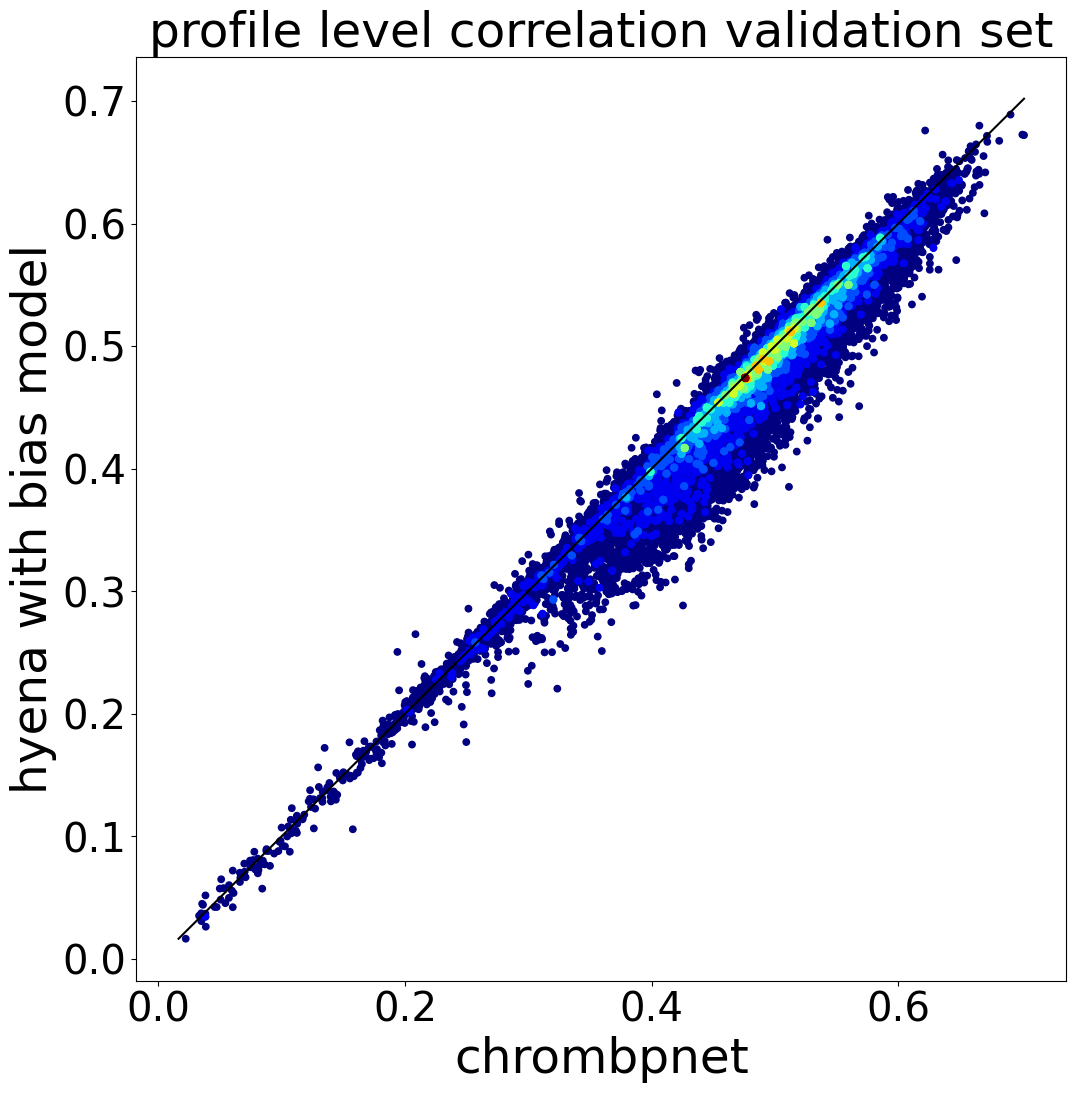

In [15]:
#now let's do the plot

import matplotlib.pyplot as plt
x,y = cbpnet_results, bias_hyena
bins = [1000, 1000] # number of bins

# histogram the data
hh, locx, locy = np.histogram2d(x, y, bins=bins)

# Sort the points by density, so that the densest points are plotted last
z = np.array([hh[np.argmax(a<=locx[1:]),np.argmax(b<=locy[1:])] for a,b in zip(x,y)])
idx = z.argsort()
x2, y2, z2 = x[idx], y[idx], z[idx]

tempmin = np.min([np.min(x), np.min(y)])
tempmax = np.max([np.max(x), np.max(y)])

plt.figure(1,figsize=(12,12)).clf()
s = plt.scatter(x2, y2, c=z2, cmap='jet', marker='.', s = 85)
plt.plot([tempmin, tempmax], [tempmin, tempmax], c='k')  
# plt.colorbar()
plt.xlabel('chrombpnet', fontsize=35)
plt.ylabel('hyena with bias model', fontsize=35)
plt.title('profile level correlation validation set', fontsize=35)
plt.tick_params(labelsize=29)
plt.show()

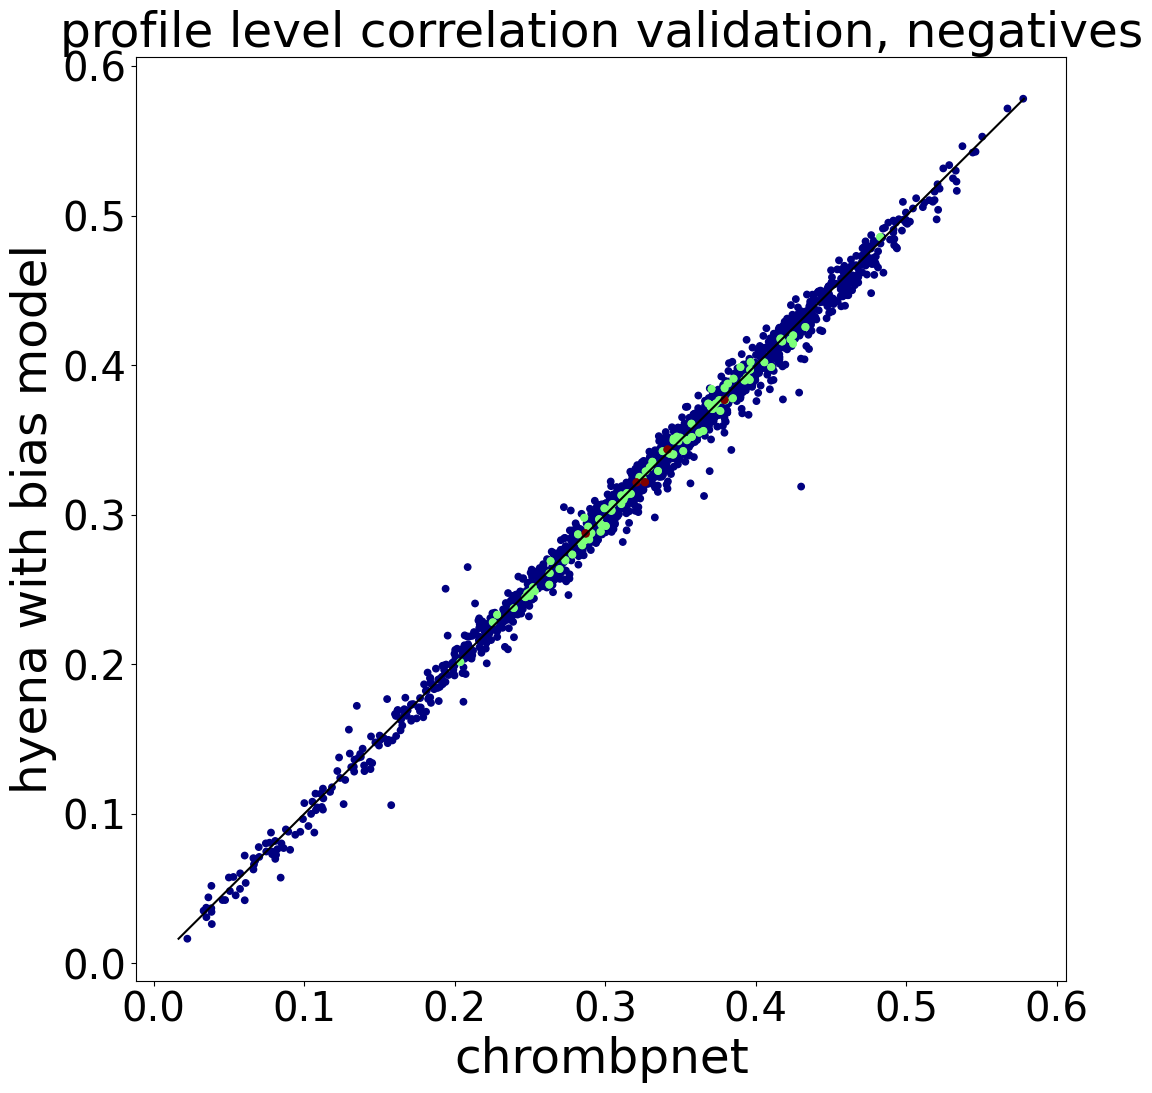

In [23]:
#let's see the plot if we only do the last negative examples (2000)
#now let's do the plot

import matplotlib.pyplot as plt
x,y = cbpnet_results[-2000:], bias_hyena[-2000:]
bins = [1000, 1000] # number of bins

# histogram the data
hh, locx, locy = np.histogram2d(x, y, bins=bins)

# Sort the points by density, so that the densest points are plotted last
z = np.array([hh[np.argmax(a<=locx[1:]),np.argmax(b<=locy[1:])] for a,b in zip(x,y)])
idx = z.argsort()
x2, y2, z2 = x[idx], y[idx], z[idx]

tempmin = np.min([np.min(x), np.min(y)])
tempmax = np.max([np.max(x), np.max(y)])

plt.figure(1,figsize=(12,12)).clf()
s = plt.scatter(x2, y2, c=z2, cmap='jet', marker='.', s = 85)
plt.plot([tempmin, tempmax], [tempmin, tempmax], c='k')  
# plt.colorbar()
plt.xlabel('chrombpnet', fontsize=35)
plt.ylabel('hyena with bias model', fontsize=35)
plt.title('profile level correlation validation, negatives', fontsize=35)
plt.tick_params(labelsize=29)
plt.show()

In [ ]:
#they perform basically evenly here, which makes sense as it's almost entirely the bias model that does the work here
#this is likely the case in the attributions too!



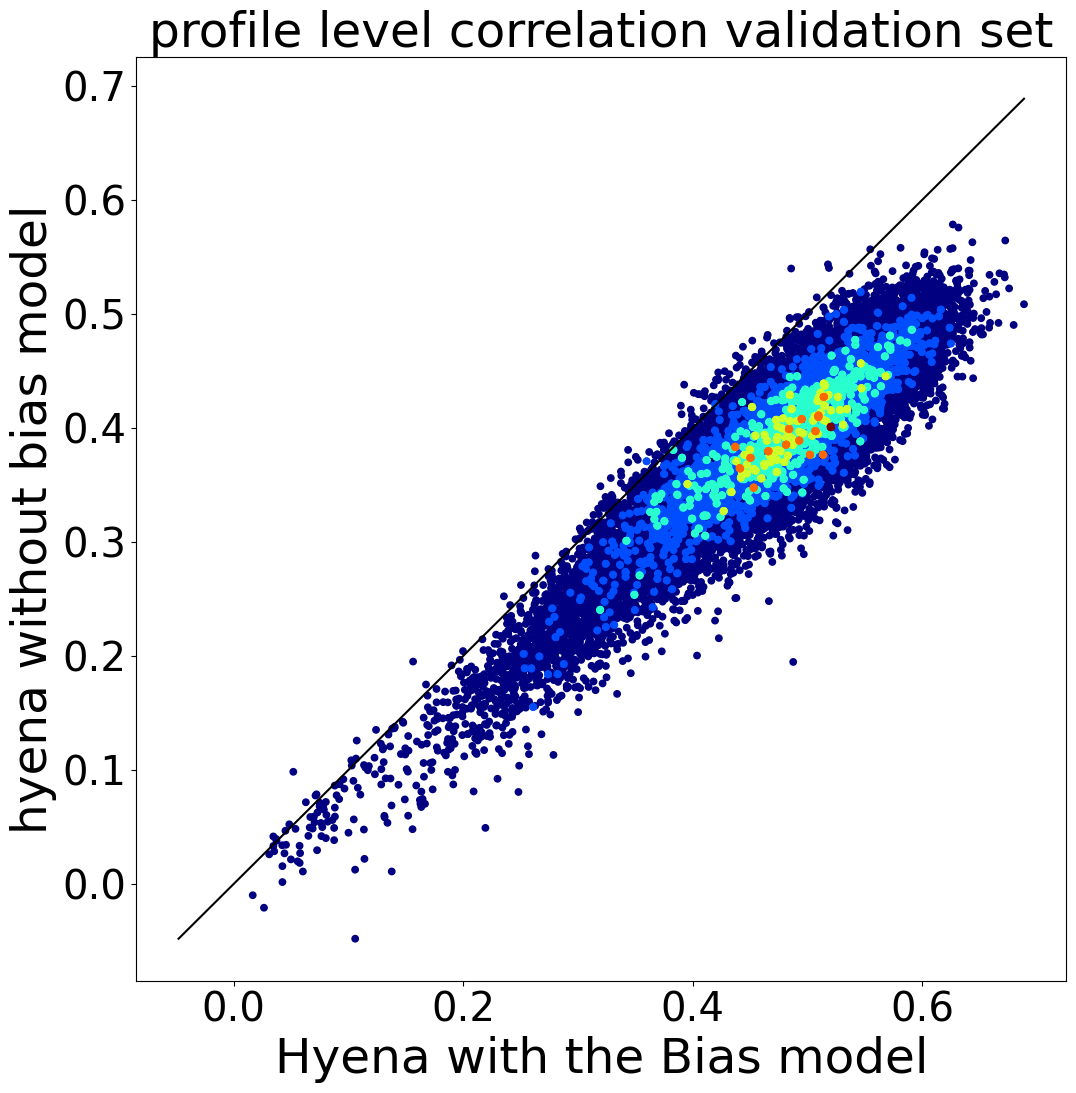

In [16]:
#now let's do the plot

import matplotlib.pyplot as plt
x,y = bias_hyena, nobias_hyena
bins = [1000, 1000] # number of bins

# histogram the data
hh, locx, locy = np.histogram2d(x, y, bins=bins)

# Sort the points by density, so that the densest points are plotted last
z = np.array([hh[np.argmax(a<=locx[1:]),np.argmax(b<=locy[1:])] for a,b in zip(x,y)])
idx = z.argsort()
x2, y2, z2 = x[idx], y[idx], z[idx]

tempmin = np.min([np.min(x), np.min(y)])
tempmax = np.max([np.max(x), np.max(y)])

plt.figure(1,figsize=(12,12)).clf()
s = plt.scatter(x2, y2, c=z2, cmap='jet', marker='.', s = 85)
plt.plot([tempmin, tempmax], [tempmin, tempmax], c='k')  
# plt.colorbar()
plt.xlabel('Hyena with the Bias model', fontsize=35)
plt.ylabel('hyena without bias model', fontsize=35)
plt.title('profile level correlation validation set', fontsize=35)
plt.tick_params(labelsize=29)
plt.show()

In [ ]:
#and of ourse let's softmax it

In [17]:
#let's softmax the data
import torch
soft_out = torch.tensor(true['profile']).softmax(dim=1)
print(soft_out.shape)
print(soft_out.sum(dim=1))
print(soft_out.sum(dim=1).shape)
soft_chbpnet = torch.tensor(chrombpnet['profile']).softmax(dim=1)
soft_bias = torch.tensor(bias['profile']).softmax(dim=1)
soft_nobias = torch.tensor(nobias['profile']).softmax(dim=1)

torch.Size([25528, 800])
tensor([1.0000, 1.0000, 1.0000,  ..., 1.0000, 1.0000, 1.0000])
torch.Size([25528])


In [18]:
#we can also do it with sofmaxed
true_profiles = true['profile']
#now test this function on the whole thing
def pearsonr2(x, y):
    # Compute Pearson correlation coefficient. We can't use `cov` or `corrcoef`
    # because they want to compute everything pairwise between rows of a
    # stacked x and y.
    xm = x.mean(axis=-1, keepdims=True)
    ym = y.mean(axis=-1, keepdims=True)
    cov = np.sum((x - xm) * (y - ym), axis=-1)/(x.shape[-1]-1)
    sx = np.std(x, ddof=1, axis=-1)
    sy = np.std(y, ddof=1, axis=-1)
    rho = cov/(sx * sy)

    return rho
cbpnet_results = pearsonr2(soft_chbpnet.numpy(), soft_out.numpy())
print('done 1')
bias_hyena = pearsonr2(soft_bias.numpy(), soft_out.numpy())
print('done2')
nobias_hyena = pearsonr2(soft_nobias.numpy(), soft_out.numpy())

#so fast!!!

done 1
done2


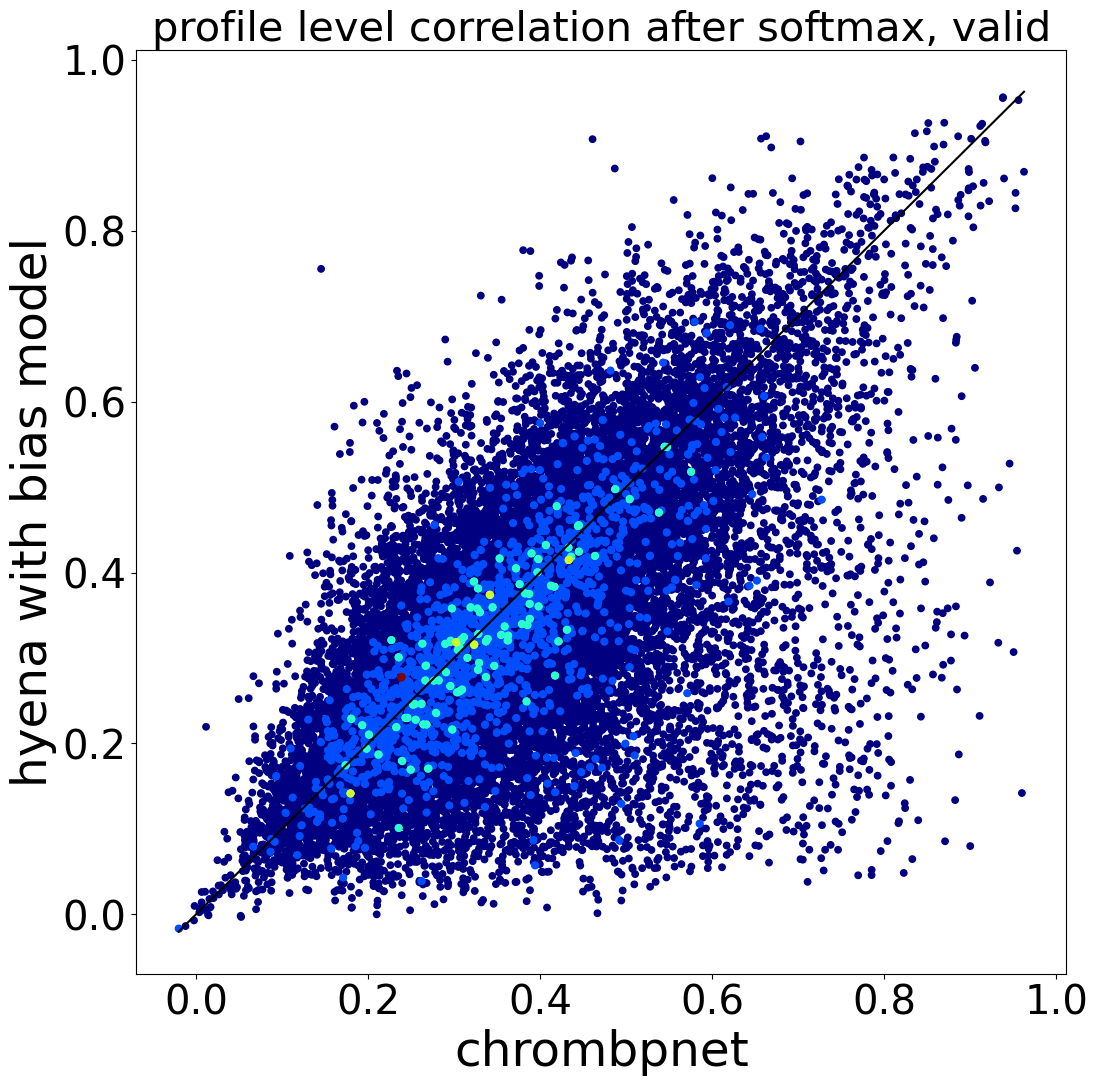

In [19]:
#now let's do the plot

import matplotlib.pyplot as plt
x,y = cbpnet_results, bias_hyena
bins = [1000, 1000] # number of bins

# histogram the data
hh, locx, locy = np.histogram2d(x, y, bins=bins)

# Sort the points by density, so that the densest points are plotted last
z = np.array([hh[np.argmax(a<=locx[1:]),np.argmax(b<=locy[1:])] for a,b in zip(x,y)])
idx = z.argsort()
x2, y2, z2 = x[idx], y[idx], z[idx]

tempmin = np.min([np.min(x), np.min(y)])
tempmax = np.max([np.max(x), np.max(y)])

plt.figure(1,figsize=(12,12)).clf()
s = plt.scatter(x2, y2, c=z2, cmap='jet', marker='.', s = 85)
plt.plot([tempmin, tempmax], [tempmin, tempmax], c='k')  
# plt.colorbar()
plt.xlabel('chrombpnet', fontsize=35)
plt.ylabel('hyena with bias model', fontsize=35)
plt.title('profile level correlation after softmax, valid', fontsize=30)
plt.tick_params(labelsize=29)

Text(0.5, 1.0, 'Profile Level Correlation')

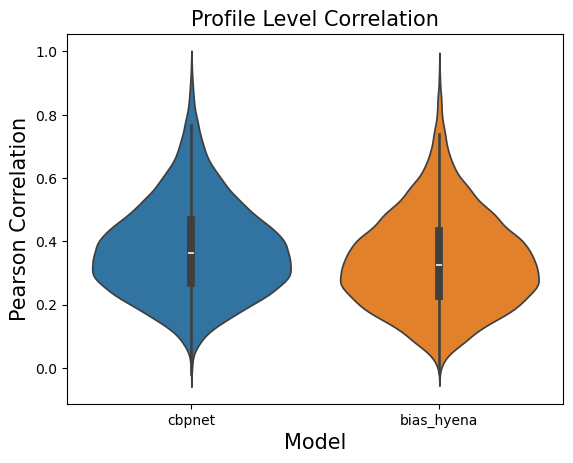

In [11]:
x,y = cbpnet_results, bias_hyena
#do a violin plot
import seaborn as sns
import pandas as pd
df = pd.DataFrame(data={'cbpnet':x, 'bias_hyena':y})
sns.violinplot(data=df)
plt.xlabel('Model', fontsize=15)
plt.ylabel('Pearson Correlation', fontsize=15)
plt.title('Profile Level Correlation', fontsize=15)

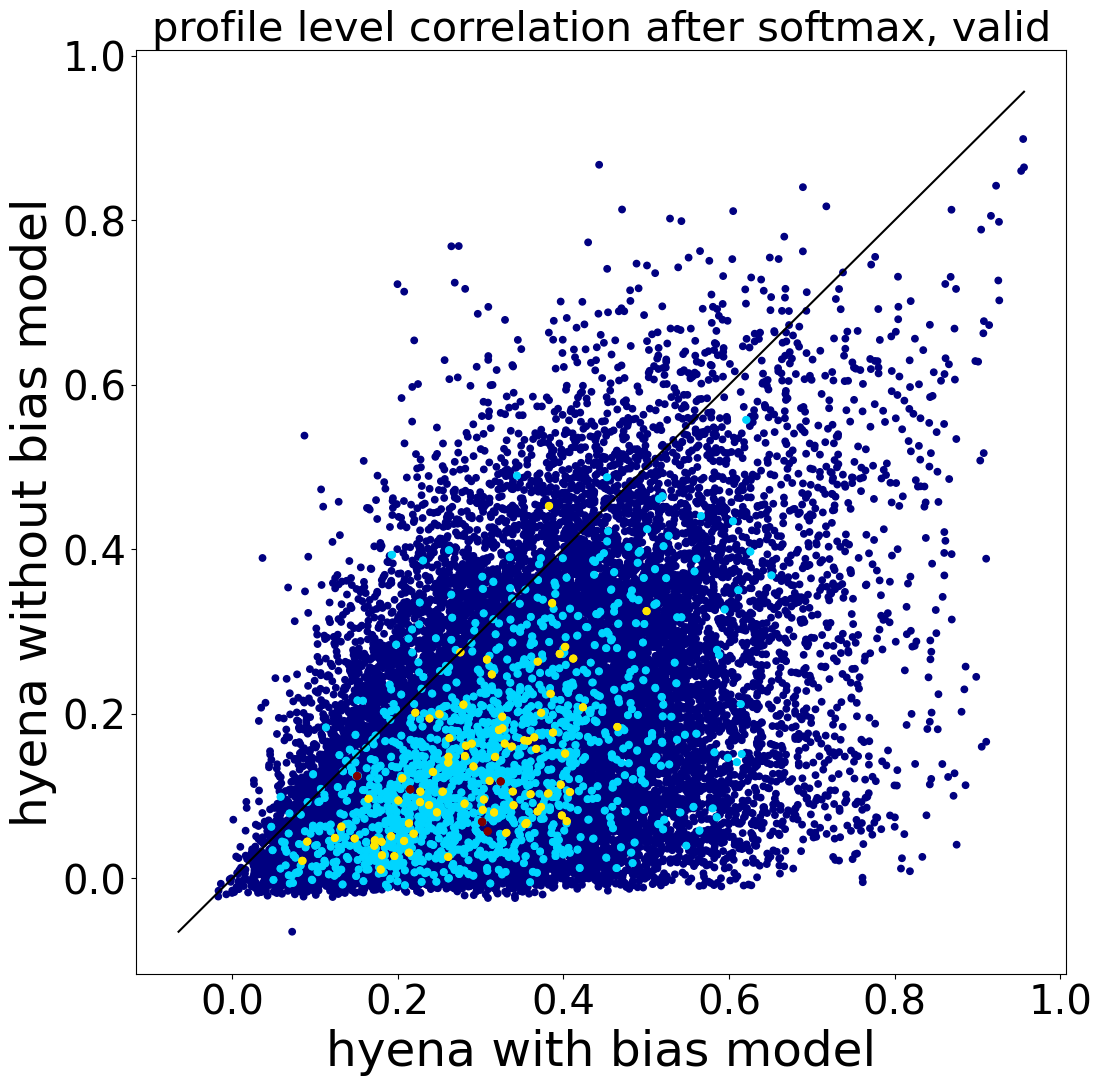

In [20]:
#now let's do the plot

import matplotlib.pyplot as plt
x,y = bias_hyena, nobias_hyena
bins = [1000, 1000] # number of bins

# histogram the data
hh, locx, locy = np.histogram2d(x, y, bins=bins)

# Sort the points by density, so that the densest points are plotted last
z = np.array([hh[np.argmax(a<=locx[1:]),np.argmax(b<=locy[1:])] for a,b in zip(x,y)])
idx = z.argsort()
x2, y2, z2 = x[idx], y[idx], z[idx]

tempmin = np.min([np.min(x), np.min(y)])
tempmax = np.max([np.max(x), np.max(y)])

plt.figure(1,figsize=(12,12)).clf()
s = plt.scatter(x2, y2, c=z2, cmap='jet', marker='.', s = 85)
plt.plot([tempmin, tempmax], [tempmin, tempmax], c='k')  
# plt.colorbar()
plt.xlabel('hyena with bias model', fontsize=35)
plt.ylabel('hyena without bias model', fontsize=35)
plt.title('profile level correlation after softmax, valid', fontsize=30)
plt.tick_params(labelsize=29)

# now evaluate the bidirectional hyena

In [1]:
#we can easily load to evaluate it like we did before, just use the test set

import sys
sys.path.append('/data/leslie/sarthak/hyena/hyena-dna/')
from evals.evals_utils import *
import numpy as np
import torch

#now let's load in the data
ckpt_path = '/data/leslie/sarthak/hyena/hyena-dna/outputs/2024-06-20/14-21-51-636002/checkpoints/139-val_loss=887.64136.ckpt'
bias_model_path = '/data/leslie/sarthak/data/chrombpnet_test/chrombpnet_model_1000/models/bias_model_scaled.h5'
#terrible practice, but I just manually set the config to be bidirectional...
util = Evals('Profile',ckpt_path, bias=bias_model_path, split='test')

In [2]:
util.dataset.seqs.shape #seems right!

(26172,)

In [3]:
targets,predicts = util.evaluate(128,0)

100%|██████████| 205/205 [00:29<00:00,  6.85it/s]


In [5]:
targets[0].shape

torch.Size([26172, 800])

In [6]:
#and save it out
np.savez_compressed('/data/leslie/sarthak/data/chrombpnet_test/saved_data_1000/profile_bias_bidirectional.npz', counts=predicts[1].numpy(), profile=predicts[0].numpy())

In [17]:
#now let's load and plot
import numpy as np
true = np.load('/data/leslie/sarthak/data/chrombpnet_test/saved_data_1000/true_data.npz')
bias = np.load('/data/leslie/sarthak/data/chrombpnet_test/saved_data_1000/profile_bias.npz')
bidirectional = np.load('/data/leslie/sarthak/data/chrombpnet_test/saved_data_1000/profile_bias_bidirectional.npz')
chbpnet = np.load('/data/leslie/sarthak/data/chrombpnet_test/saved_data_1000/profile_chbpnet.npz')

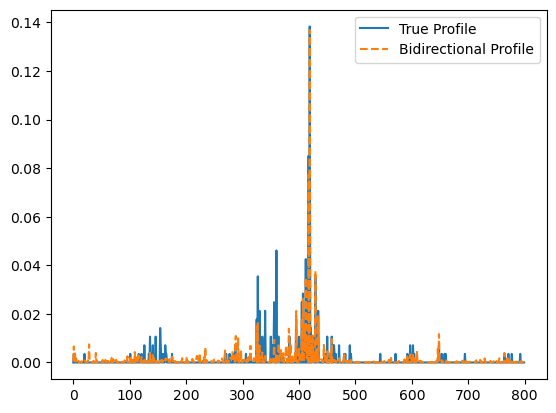

In [14]:
#now plot
import matplotlib.pyplot as plt
plt.plot(true['profile'][0]/true['profile'][0].sum(), label='True Profile')
# plt.plot(bias['profile'][0], label='Bias Profile')
plt.plot(torch.tensor(bidirectional['profile'][0]).softmax(dim=0), label='Bidirectional Profile', linestyle='--')

plt.legend()

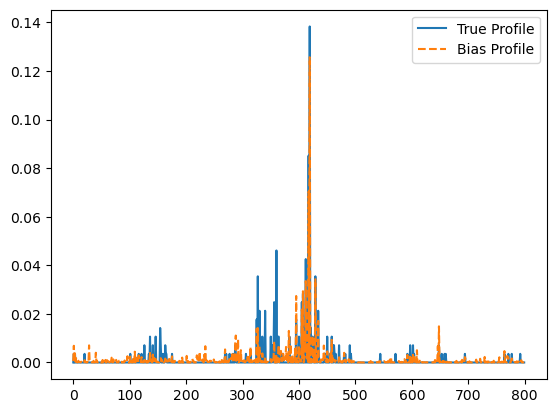

In [15]:
#now plot
import matplotlib.pyplot as plt
plt.plot(true['profile'][0]/true['profile'][0].sum(), label='True Profile')
# plt.plot(bias['profile'][0], label='Bias Profile')
plt.plot(torch.tensor(bias['profile'][0]).softmax(dim=0), label='Bias Profile', linestyle='--')

plt.legend()

In [29]:
#now test this function on the whole thing
true_profiles = true['profile']
def pearsonr2(x, y):
    # Compute Pearson correlation coefficient. We can't use `cov` or `corrcoef`
    # because they want to compute everything pairwise between rows of a
    # stacked x and y.
    xm = x.mean(axis=-1, keepdims=True)
    ym = y.mean(axis=-1, keepdims=True)
    cov = np.sum((x - xm) * (y - ym), axis=-1)/(x.shape[-1]-1)
    sx = np.std(x, ddof=1, axis=-1)
    sy = np.std(y, ddof=1, axis=-1)
    rho = cov/(sx * sy)

    return rho
cbpnet_results = pearsonr2(chbpnet['profile'], true_profiles)
print('done 1')
bias_hyena = pearsonr2(bias['profile'], true_profiles)
print('done2')
bidirectional_hyena = pearsonr2(bidirectional['profile'], true_profiles)

#so fast!!!

done 1
done2


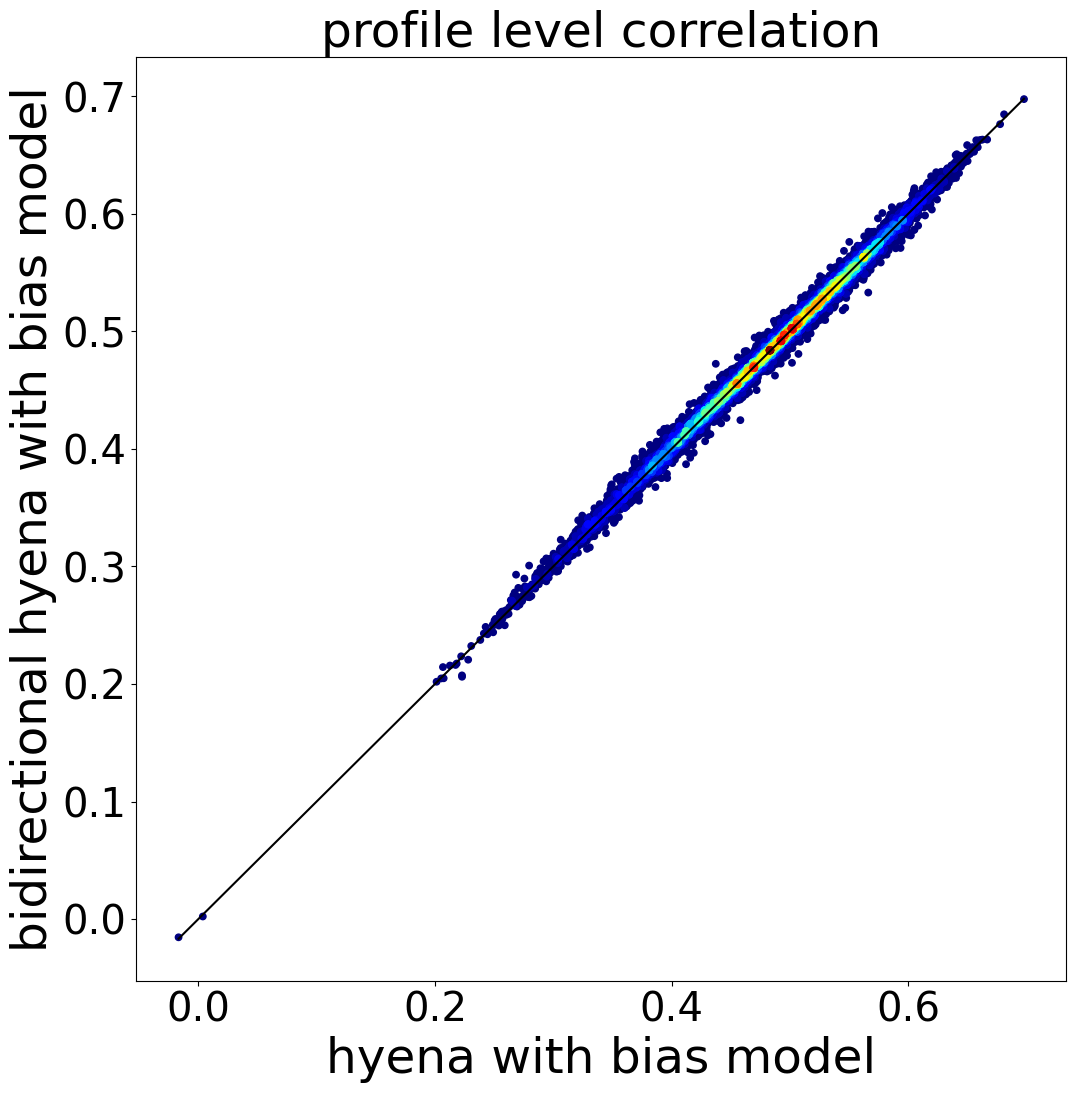

In [20]:
#now do the scatter plt
import matplotlib.pyplot as plt
x,y = bias_hyena, bidirectional_hyena
bins = [1000, 1000] # number of bins

# histogram the data
hh, locx, locy = np.histogram2d(x, y, bins=bins)

# Sort the points by density, so that the densest points are plotted last
z = np.array([hh[np.argmax(a<=locx[1:]),np.argmax(b<=locy[1:])] for a,b in zip(x,y)])
idx = z.argsort()
x2, y2, z2 = x[idx], y[idx], z[idx]

tempmin = np.min([np.min(x), np.min(y)])
tempmax = np.max([np.max(x), np.max(y)])

plt.figure(1,figsize=(12,12)).clf()
s = plt.scatter(x2, y2, c=z2, cmap='jet', marker='.', s = 85)
plt.plot([tempmin, tempmax], [tempmin, tempmax], c='k')  
# plt.colorbar()
plt.xlabel('hyena with bias model', fontsize=35)
plt.ylabel('bidirectional hyena with bias model', fontsize=35)
plt.title('profile level correlation', fontsize=35)
plt.tick_params(labelsize=29)

#ok so seems like there's almost no difference with the bidirectional flag... so we can just use the normal one

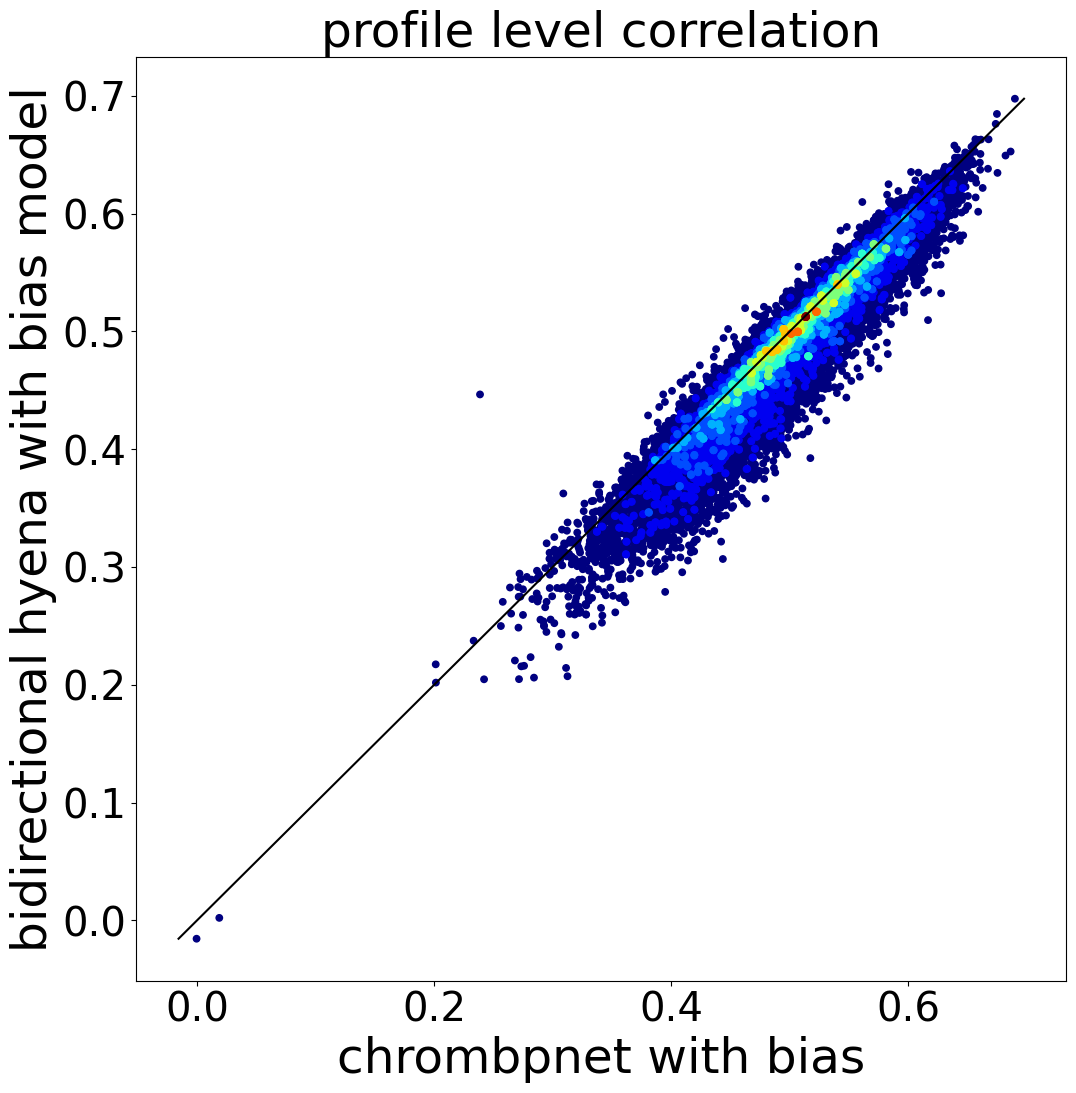

In [30]:
#but let's verify with 
x,y = cbpnet_results, bidirectional_hyena
bins = [1000, 1000] # number of bins

# histogram the data
hh, locx, locy = np.histogram2d(x, y, bins=bins)

# Sort the points by density, so that the densest points are plotted last
z = np.array([hh[np.argmax(a<=locx[1:]),np.argmax(b<=locy[1:])] for a,b in zip(x,y)])
idx = z.argsort()
x2, y2, z2 = x[idx], y[idx], z[idx]

tempmin = np.min([np.min(x), np.min(y)])
tempmax = np.max([np.max(x), np.max(y)])

plt.figure(1,figsize=(12,12)).clf()
s = plt.scatter(x2, y2, c=z2, cmap='jet', marker='.', s = 85)
plt.plot([tempmin, tempmax], [tempmin, tempmax], c='k')  
# plt.colorbar()
plt.xlabel('chrombpnet with bias', fontsize=35)
plt.ylabel('bidirectional hyena with bias model', fontsize=35)
plt.title('profile level correlation', fontsize=35)
plt.tick_params(labelsize=29)

In [22]:
chbpnet['profile'].shape

(26172, 800)

In [31]:
#let's do it after the softmax again
# true_profiles = torch.tensor(true['profile']).softmax(dim=1).numpy()
true_profiles = true['profile'] #it's actually an issue to softmax the true profiles!
cbpnet_results = pearsonr2(torch.tensor(chbpnet['profile']).softmax(dim=1).numpy(), true_profiles)
print('done 1')
bias_hyena = pearsonr2(torch.tensor(bias['profile']).softmax(dim=1).numpy(), true_profiles)
print('done2')
bidirectional_hyena = pearsonr2(torch.tensor(bidirectional['profile']).softmax(dim=1).numpy(), true_profiles)

done 1
done2


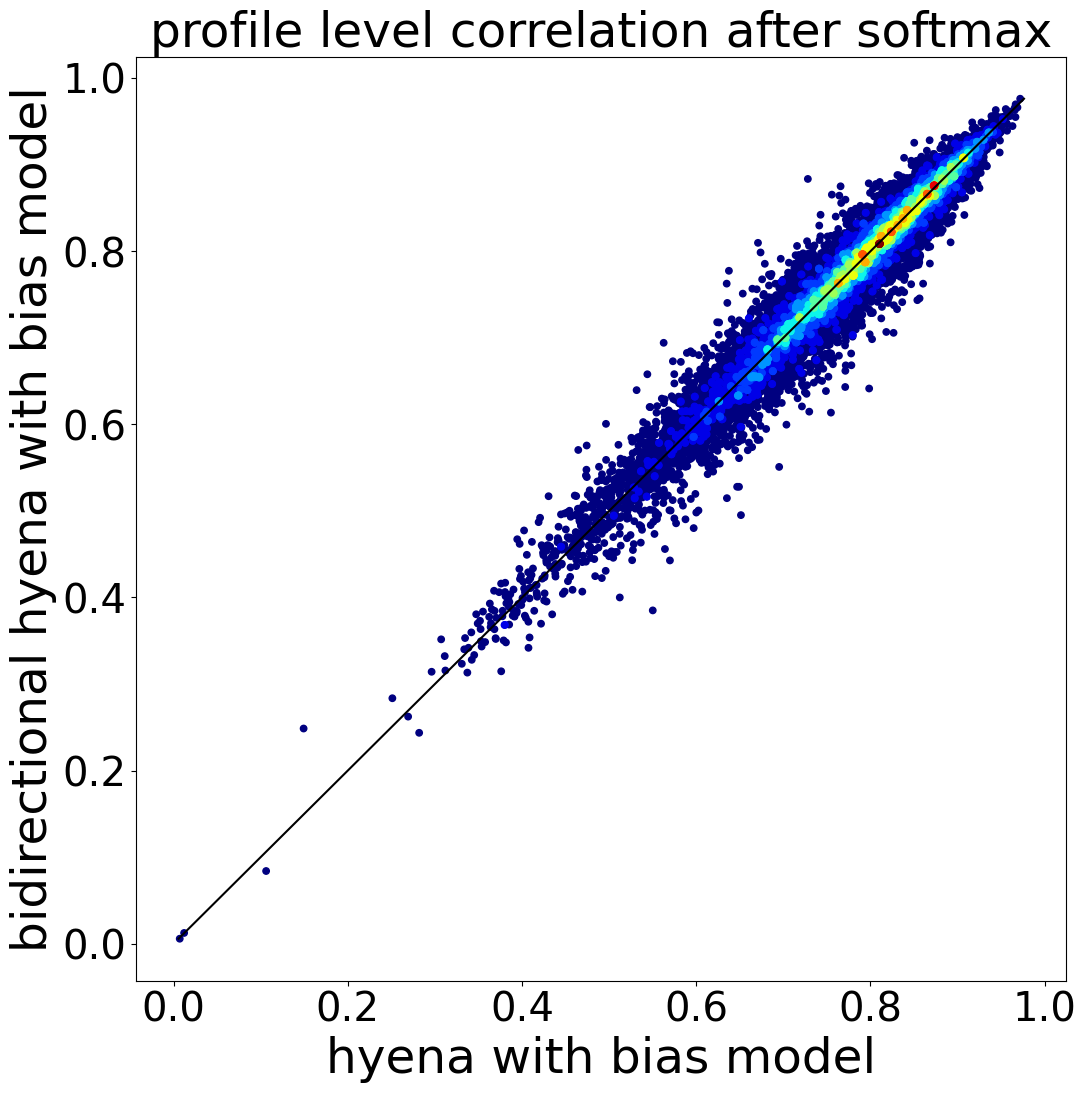

In [33]:
#now do the scatter plt
import matplotlib.pyplot as plt
x,y = bias_hyena, bidirectional_hyena
bins = [1000, 1000] # number of bins

# histogram the data
hh, locx, locy = np.histogram2d(x, y, bins=bins)

# Sort the points by density, so that the densest points are plotted last
z = np.array([hh[np.argmax(a<=locx[1:]),np.argmax(b<=locy[1:])] for a,b in zip(x,y)])
idx = z.argsort()
x2, y2, z2 = x[idx], y[idx], z[idx]

tempmin = np.min([np.min(x), np.min(y)])
tempmax = np.max([np.max(x), np.max(y)])

plt.figure(1,figsize=(12,12)).clf()
s = plt.scatter(x2, y2, c=z2, cmap='jet', marker='.', s = 85)
plt.plot([tempmin, tempmax], [tempmin, tempmax], c='k')  
# plt.colorbar()
plt.xlabel('hyena with bias model', fontsize=35)
plt.ylabel('bidirectional hyena with bias model', fontsize=35)
plt.title('profile level correlation after softmax', fontsize=35)
plt.tick_params(labelsize=29)

#ok so seems like there's almost no difference with the bidirectional flag... so we can just use the normal one

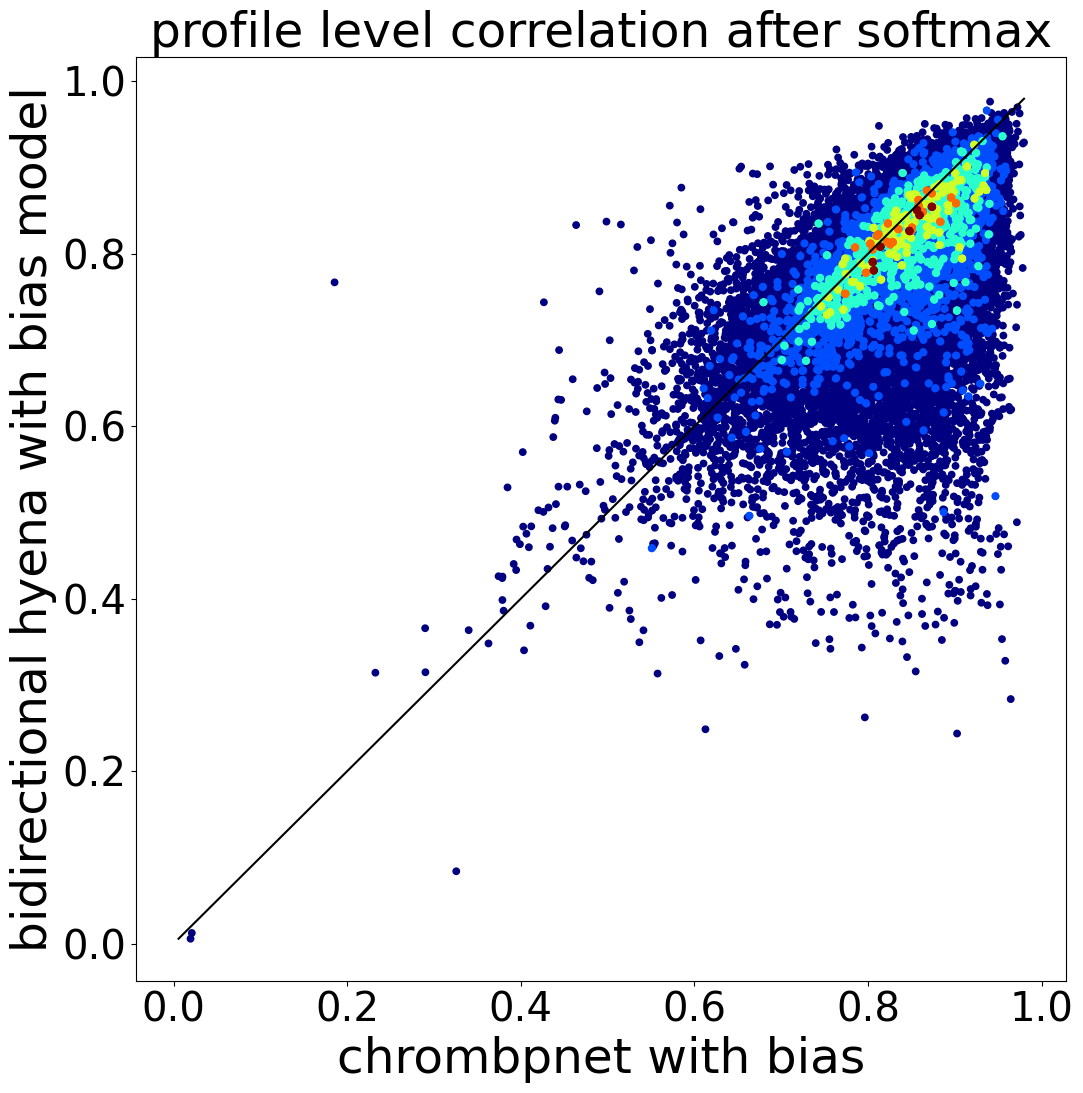

In [34]:
#but let's verify with 
x,y = cbpnet_results, bidirectional_hyena
bins = [1000, 1000] # number of bins

# histogram the data
hh, locx, locy = np.histogram2d(x, y, bins=bins)

# Sort the points by density, so that the densest points are plotted last
z = np.array([hh[np.argmax(a<=locx[1:]),np.argmax(b<=locy[1:])] for a,b in zip(x,y)])
idx = z.argsort()
x2, y2, z2 = x[idx], y[idx], z[idx]

tempmin = np.min([np.min(x), np.min(y)])
tempmax = np.max([np.max(x), np.max(y)])

plt.figure(1,figsize=(12,12)).clf()
s = plt.scatter(x2, y2, c=z2, cmap='jet', marker='.', s = 85)
plt.plot([tempmin, tempmax], [tempmin, tempmax], c='k')  
# plt.colorbar()
plt.xlabel('chrombpnet with bias', fontsize=35)
plt.ylabel('bidirectional hyena with bias model', fontsize=35)
plt.title('profile level correlation after softmax', fontsize=35)
plt.tick_params(labelsize=29)

In [35]:
#see how many are higher for x vs y
z = x>y
print(z.sum(), z.shape[0]) #so it's about 50/50

18654 26172


Text(0.5, 1.0, 'Profile Level Correlation')

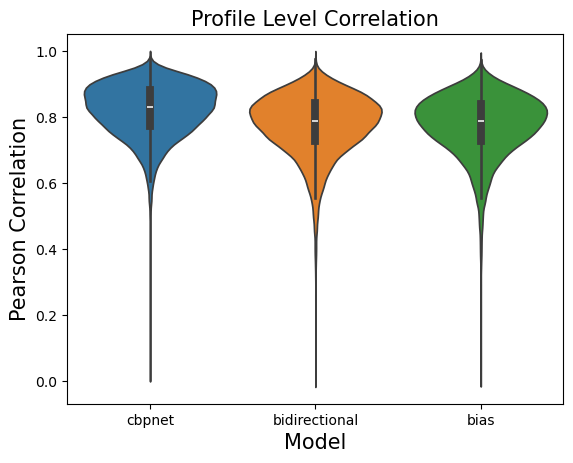

In [37]:
#violin plot
import seaborn as sns
import pandas as pd
df = pd.DataFrame(data={'cbpnet':x, 'bidirectional':y, 'bias':bias_hyena})

sns.violinplot(data=df)
plt.xlabel('Model', fontsize=15)
plt.ylabel('Pearson Correlation', fontsize=15)
plt.title('Profile Level Correlation', fontsize=15)


In [38]:
#do a t test to see if the 3 groups are the same
import scipy.stats as stats
stats.ttest_ind(x,y) #p value is 0, but when have 20000 it will be

TtestResult(statistic=59.26540690994225, pvalue=0.0, df=52342.0)

In [39]:
stats.ttest_ind(bias_hyena,y) #wait these are not different! huh...

TtestResult(statistic=-0.43333490277533315, pvalue=0.6647732709556332, df=52342.0)

# final results looking at hyena based bias then larger output network

In [1]:
#the loss isn't that promising

#the key idea tho is we need to modify the task to be the larger network or the smaller one!

import sys
sys.path.append('/data/leslie/sarthak/hyena/hyena-dna/')
from evals.evals_utils import *
import numpy as np
import torch

#now let's load in the data
ckpt_path = '/data/leslie/sarthak/hyena/hyena-dna/outputs/2024-06-22/23-03-43-251150/checkpoints/111-val_loss=888.26544.ckpt'
bias_model_path = '/data/leslie/sarthak/data/chrombpnet_test/chrombpnet_model_1000/models/bias_model_scaled.h5'
#terrible practice, but I just manually set the config to be bidirectional...
util_ = Evals('Profile',ckpt_path, bias=bias_model_path, split='test', linear_profile=False)

KeyError: 'decoder.0.output_transform_profile.weight'

In [4]:
#let's test this decoder_state_dict
import torch
import yaml
ckpt_path = '/data/leslie/sarthak/hyena/hyena-dna/outputs/2024-06-22/23-03-43-251150/checkpoints/111-val_loss=888.26544.ckpt'
cfg = '/data/leslie/sarthak/hyena/hyena-dna/configs/evals/profile.yaml'
cfg = yaml.load(open(cfg, 'r'), Loader=yaml.FullLoader)
train_cfg = cfg['train']
model_cfg = cfg['model_config']
d_output = train_cfg['d_output']
state_dict = torch.load(ckpt_path, map_location='cpu')
torch.nn.modules.utils.consume_prefix_in_state_dict_if_present(
    state_dict["state_dict"], "model."
)
model_state_dict = state_dict["state_dict"]
# need to remove torchmetrics. to remove keys, need to convert to list first
for key in list(model_state_dict.keys()):
    if "torchmetrics" in key:
        model_state_dict.pop(key)
# the state_dict keys slightly mismatch from Lightning..., so we fix it here
decoder_state_dict = {}

In [6]:
model_state_dict.keys() #ahh so we have a lot of these other ones!

odict_keys(['decoder.0.output_transform_counts.weight', 'decoder.0.output_transform_counts.bias', 'decoder.0.output_transform_profile.0.weight', 'decoder.0.output_transform_profile.0.bias', 'decoder.0.output_transform_profile.2.weight', 'decoder.0.output_transform_profile.2.bias', 'backbone.embeddings.word_embeddings.weight', 'backbone.layers.0.mixer.filter_fn.bias', 'backbone.layers.0.mixer.filter_fn.implicit_filter.0.bias', 'backbone.layers.0.mixer.filter_fn.implicit_filter.0.weight', 'backbone.layers.0.mixer.filter_fn.implicit_filter.1.freq', 'backbone.layers.0.mixer.filter_fn.implicit_filter.2.bias', 'backbone.layers.0.mixer.filter_fn.implicit_filter.2.weight', 'backbone.layers.0.mixer.filter_fn.implicit_filter.3.freq', 'backbone.layers.0.mixer.filter_fn.implicit_filter.4.bias', 'backbone.layers.0.mixer.filter_fn.implicit_filter.4.weight', 'backbone.layers.0.mixer.filter_fn.implicit_filter.5.freq', 'backbone.layers.0.mixer.filter_fn.implicit_filter.6.weight', 'backbone.layers.0.mix

In [7]:
for key in list(model_state_dict.keys()):
    if 'decoder' in key:
        decoder_state_dict[key[10:]] = model_state_dict.pop(key) #still gotta test this, but I think it'll work
print(decoder_state_dict)

{'output_transform_counts.weight': tensor([[-0.0909,  0.2816, -0.1006,  0.0323,  0.0018, -0.1162,  0.0303, -0.1273,
         -0.0722,  0.1294, -0.1482, -0.1839, -0.1488,  0.1774, -0.1124,  0.0974,
          0.1837,  0.1038, -0.1410, -0.1031, -0.1316,  0.0917, -0.0819, -0.1527,
         -0.1577,  0.0363,  0.0550, -0.1826,  0.0686, -0.1617,  0.1583, -0.0098,
          0.1413, -0.0472,  0.0461, -0.1450,  0.1375,  0.0902, -0.1393,  0.1033,
         -0.1921,  0.1581,  0.1497,  0.2070, -0.1653, -0.1611, -0.1436, -0.1638,
         -0.1671, -0.0839,  0.0842, -0.0214, -0.0930,  0.0404, -0.1673, -0.1825,
         -0.0422,  0.0671,  0.1693,  0.0410,  0.0764,  0.1516,  0.0446,  0.1784,
         -0.2215,  0.1385,  0.2887, -0.0649, -0.2276,  0.1531,  0.1142, -0.1786,
          0.2096,  0.1564, -0.1549,  0.1168, -0.1538, -0.1655,  0.1149, -0.0375,
          0.1786, -0.1182,  0.0409, -0.2360,  0.0901, -0.1013,  0.1215, -0.0083,
         -0.1727,  0.1919,  0.0751,  0.0138,  0.0747,  0.1124, -0.1280, -0

In [11]:
from src.dataloaders.datasets.hg38_char_tokenizer import CharacterTokenizer
from src.models.sequence.dna_embedding import DNAEmbeddingModel
from src.tasks.decoders import ProfileDecoder
backbone = DNAEmbeddingModel(**model_cfg)
decoder = ProfileDecoder(model_cfg['d_model'], d_output=d_output, l_output=0, mode='pool', linear_profile=False)

In [12]:
decoder

ProfileDecoder(
  (output_transform_counts): Linear(in_features=128, out_features=1, bias=True)
  (output_transform_profile): Sequential(
    (0): Linear(in_features=128, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=1, bias=True)
  )
)

In [13]:
decoder.load_state_dict(decoder_state_dict, strict=True) #ahh this works!!

<All keys matched successfully>

In [ ]:
#and now the models with bias, this is bias on the actual output
import sys
sys.path.append('/data/leslie/sarthak/hyena/hyena-dna/')
from evals.evals_utils import *
import numpy as np
import torch

#now let's load in the data
ckpt_path = '/data/leslie/sarthak/hyena/hyena-dna/outputs/2024-06-21/18-21-05-697071/checkpoints/76-val_loss=1463.96204.ckpt'
bias_model_path = '/data/leslie/sarthak/data/chrombpnet_test/chrombpnet_model_1000/models/bias_model_scaled.h5'

In [ ]:
#this is bias with the hidden state
ckpt_path = '/data/leslie/sarthak/hyena/hyena-dna/outputs/2024-06-21/18-19-19-663953/checkpoints/109-val_loss=1456.93091.ckpt'